# Predicción del bajo peso al nacer en Colombia
## Proyecto final - Metodología CRISP-DM

**Universidad de los Llanos - Introducción a la Analítica de Datos (Computación 3)**

Integrantes:
Jhorman Alexander Carrillo Perez - 160004505
Daniel Felipe Villegas - 160004844

Datos: Estadísticas Vitales (EEVV) 2023 del DANE, base de nacimientos.
https://microdatos.dane.gov.co/index.php/catalog/876

---

Este notebook recorre las seis fases de CRISP-DM en orden.

| Fase | Contenido |
|---|---|
| 1. Entendimiento del negocio | Problema, objetivos y criterios de éxito |
| 2. Entendimiento de los datos | Calidad de la base y relación de las variables con el bajo peso |
| 3. Preparación de los datos | Selección de variables, limpieza, codificación y escalado |
| 4. Modelado | Árbol de decisión y regresión logística |
| 5. Evaluación | Resultados en el conjunto de prueba y selección del modelo |
| 6. Despliegue | Exportación del modelo para la aplicación |

# Fase 1. Entendimiento del negocio

**Contexto.** El bajo peso al nacer, definido por la OMS como un peso inferior a 2.500 g, se asocia con mayor riesgo de muerte en el primer año de vida y de problemas de salud y desarrollo posteriores. En Colombia, cada nacimiento queda registrado en el certificado de nacido vivo, que el DANE consolida en las Estadísticas Vitales.

**Problema.** La Secretaría de Salud del Meta, como cualquier entidad territorial, tiene recursos limitados para el seguimiento prenatal. Si se pudiera estimar durante el embarazo qué gestantes tienen mayor riesgo de tener un bebé con bajo peso, se podría priorizar su control y atención.

**Objetivo del negocio.** Apoyar la identificación temprana de embarazos con riesgo de bajo peso al nacer, a partir de información de la madre y de la gestación que se conoce antes del parto.

**Objetivo de analítica.** Entrenar y comparar dos modelos de clasificación (árbol de decisión y regresión logística) que predigan si un nacimiento será de bajo peso (sí / no). Los modelos se entrenan con los nacimientos de todo el país, porque los del Meta solos son pocos para aprender bien la clase minoritaria. El mejor modelo se integra en una aplicación con interfaz gráfica.

**Criterios de éxito.**
- Detectar una proporción alta de los casos reales de bajo peso (*recall* de la clase "bajo peso"). Se prioriza esta métrica porque no detectar un embarazo de riesgo es más grave que dar una falsa alarma.
- Superar a la línea base de predecir siempre "peso normal", que acierta en la mayoría de los casos pero no detecta ninguno de bajo peso. Por eso la exactitud (*accuracy*) sola no sirve para evaluar.
- El valor mínimo de *recall* se fijará después del primer modelo, como parte de la iteración propia de CRISP-DM.

**Alcance y limitaciones.** Es una herramienta académica de apoyo, no un diagnóstico médico. Solo usa las variables del certificado de nacido vivo, así que no incluye factores clínicos como el estado nutricional de la madre, enfermedades previas o consumo de tabaco.

---

# Fase 2. Entendimiento de los datos

En esta fase se carga la base, se revisa su calidad y se explora qué variables se relacionan con el bajo peso. No se modifica ni se limpia nada todavía: eso corresponde a la fase 3 (preparación de los datos).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

plt.style.use('ggplot')

## 2.1 Carga de los datos


In [2]:
RUTA = '/content/BD-EEVV-Nacimientos-2023.csv'

df = pd.read_csv(RUTA, dtype=str, keep_default_na=False, encoding='latin-1')

print('Dimensiones (filas, columnas):', df.shape)
df.head()

Dimensiones (filas, columnas): (515549, 39)


,COD_DPTO,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
0,23,417,1,1,,1,8,5,2023,01,...,2,25/09/2015,2,2,2,44,99,99,1,1
1,11,001,1,1,,2,6,4,2023,02,...,1,,1,1,1,35,11,3,1,1
2,11,001,1,1,,1,6,4,2023,07,...,1,,1,1,1,32,09,6,1,1
3,11,001,1,1,,1,6,5,2023,02,...,1,,1,1,1,34,09,5,1,1
4,11,001,1,1,,1,6,5,2023,10,...,2,16/05/2021,2,1,1,37,10,2,1,1


In [3]:
print(df.columns.tolist())

['COD_DPTO', 'COD_MUNIC', 'AREANAC', 'SIT_PARTO', 'OTRO_SIT', 'SEXO', 'PESO_NAC', 'TALLA_NAC', 'ANO', 'MES', 'ATEN_PAR', 'T_GES', 'T_GES_AGRU_CIE', 'NUMCONSUL', 'TIPO_PARTO', 'MUL_PARTO', 'APGAR1', 'APGAR2', 'IDHEMOCLAS', 'IDFACTORRH', 'IDPERTET', 'EDAD_MADRE', 'EST_CIVM', 'NIV_EDUM', 'ULTCURMAD', 'CODPRES', 'CODPTORE', 'CODMUNRE', 'AREA_RES', 'N_HIJOSV', 'FECHA_NACM', 'N_EMB', 'SEG_SOCIAL', 'IDCLASADMI', 'EDAD_PADRE', 'NIV_EDUP', 'ULTCURPAD', 'PROFESION', 'TIPOFORMULARIO']


La base tiene **515.549 nacimientos y 39 variables**, lo que coincide con los casos válidos que reporta la documentación del DANE.

Casi todas las variables son **códigos**, no valores reales. Por ejemplo, `PESO_NAC = 6` no son 6 gramos sino el rango 3.000-3.499 g. Por eso es indispensable el diccionario de datos.

## 2.2 Diccionario de datos

Etiquetas de las variables principales, copiadas de la documentación oficial.

In [4]:
# Etiquetas tomadas del diccionario de datos del DANE (documentación del catálogo 876)
etiquetas = {
    'PESO_NAC': {'1': 'Menos de 1.000 g', '2': '1.000-1.499 g', '3': '1.500-1.999 g', '4': '2.000-2.499 g',
                 '5': '2.500-2.999 g', '6': '3.000-3.499 g', '7': '3.500-3.999 g', '8': '4.000 g y más',
                 '9': 'Sin información'},
    'T_GES_AGRU_CIE': {'1': 'Menos de 22 sem', '2': '22 a 27 sem', '3': '28 a 36 sem', '4': '37 a 41 sem',
                       '5': '42 sem y más', '6': 'Ignorado', '9': 'Sin información'},
    'MUL_PARTO': {'1': 'Simple', '2': 'Doble', '3': 'Triple', '4': 'Cuádruple o más', '9': 'Sin información'},
    'EDAD_MADRE': {'1': '10-14', '2': '15-19', '3': '20-24', '4': '25-29', '5': '30-34', '6': '35-39',
                   '7': '40-44', '8': '45-49', '9': '50-54', '99': 'Sin información'},
    'NIV_EDUM': {'01': 'Preescolar', '02': 'Básica primaria', '03': 'Básica secundaria', '04': 'Media académica',
                 '05': 'Media técnica', '06': 'Normalista', '07': 'Técnica profesional', '08': 'Tecnológica',
                 '09': 'Profesional', '10': 'Especialización', '11': 'Maestría', '12': 'Doctorado',
                 '13': 'Ninguno', '99': 'Sin información'},
    'SEG_SOCIAL': {'1': 'Contributivo', '2': 'Subsidiado', '3': 'Excepción', '4': 'Especial',
                   '5': 'No asegurado', '9': 'Sin información'},
    'AREA_RES': {'1': 'Cabecera municipal', '2': 'Centro poblado', '3': 'Rural disperso', '9': 'Sin información',
                 '': 'Vacío'},
    'SEXO': {'1': 'Masculino', '2': 'Femenino', '3': 'Indeterminado'},
}

departamentos = {'05': 'Antioquia', '08': 'Atlántico', '11': 'Bogotá', '13': 'Bolívar', '15': 'Boyacá',
    '17': 'Caldas', '18': 'Caquetá', '19': 'Cauca', '20': 'Cesar', '23': 'Córdoba', '25': 'Cundinamarca',
    '27': 'Chocó', '41': 'Huila', '44': 'La Guajira', '47': 'Magdalena', '50': 'Meta', '52': 'Nariño',
    '54': 'Norte de Santander', '63': 'Quindío', '66': 'Risaralda', '68': 'Santander', '70': 'Sucre',
    '73': 'Tolima', '76': 'Valle del Cauca', '81': 'Arauca', '85': 'Casanare', '86': 'Putumayo',
    '88': 'San Andrés', '91': 'Amazonas', '94': 'Guainía', '95': 'Guaviare', '97': 'Vaupés', '99': 'Vichada'}

## 2.3 Calidad de los datos

### Datos faltantes

En esta base los faltantes aparecen de dos formas: celdas vacías y **códigos especiales** (9, 99 o 999) que el diccionario define como "Sin información". Un `isnull()` no detecta los segundos, así que se cuentan variable por variable.

In [5]:
# Códigos que el diccionario define como "Sin información" o "Ignorado" en cada variable
sin_info = {
    'AREANAC': ['9'], 'SIT_PARTO': ['9'], 'SEXO': ['3'], 'PESO_NAC': ['9'], 'TALLA_NAC': ['9'],
    'ATEN_PAR': ['9'], 'T_GES': ['6', '9'], 'T_GES_AGRU_CIE': ['6', '9'], 'NUMCONSUL': ['99'],
    'TIPO_PARTO': ['4', '9'], 'MUL_PARTO': ['9'], 'APGAR1': ['99'], 'APGAR2': ['99'],
    'IDHEMOCLAS': ['9'], 'IDFACTORRH': ['9'], 'IDPERTET': ['9'], 'EDAD_MADRE': ['99'], 'EST_CIVM': ['9'],
    'NIV_EDUM': ['99'], 'ULTCURMAD': ['99'], 'AREA_RES': ['9'], 'N_HIJOSV': ['99'], 'N_EMB': ['99'],
    'SEG_SOCIAL': ['9'], 'IDCLASADMI': ['9'], 'EDAD_PADRE': ['999'], 'NIV_EDUP': ['99'],
    'ULTCURPAD': ['99'], 'PROFESION': ['9'],
}

filas = []
for col in df.columns:
    pct_vacio = (df[col].str.strip() == '').mean() * 100
    pct_codigo = df[col].isin(sin_info.get(col, [])).mean() * 100
    filas.append({'columna': col, 'valores_unicos': df[col].nunique(),
                  '%_vacio': round(pct_vacio, 2), '%_sin_informacion': round(pct_codigo, 2),
                  '%_faltante_total': round(pct_vacio + pct_codigo, 2)})

calidad = pd.DataFrame(filas).sort_values('%_faltante_total', ascending=False).reset_index(drop=True)
calidad

,columna,valores_unicos,%_vacio,%_sin_informacion,%_faltante_total
0,OTRO_SIT,577,99.80,0.00,99.80
1,FECHA_NACM,8305,47.33,0.00,47.33
2,ULTCURPAD,15,0.00,9.41,9.41
3,NIV_EDUP,14,0.00,9.39,9.39
4,IDCLASADMI,6,4.59,0.87,5.45
5,ULTCURMAD,15,0.00,3.49,3.49
6,NIV_EDUM,14,0.00,3.49,3.49
7,EST_CIVM,7,0.00,2.80,2.80
8,APGAR1,11,0.00,2.32,2.32
9,APGAR2,11,0.00,2.32,2.32


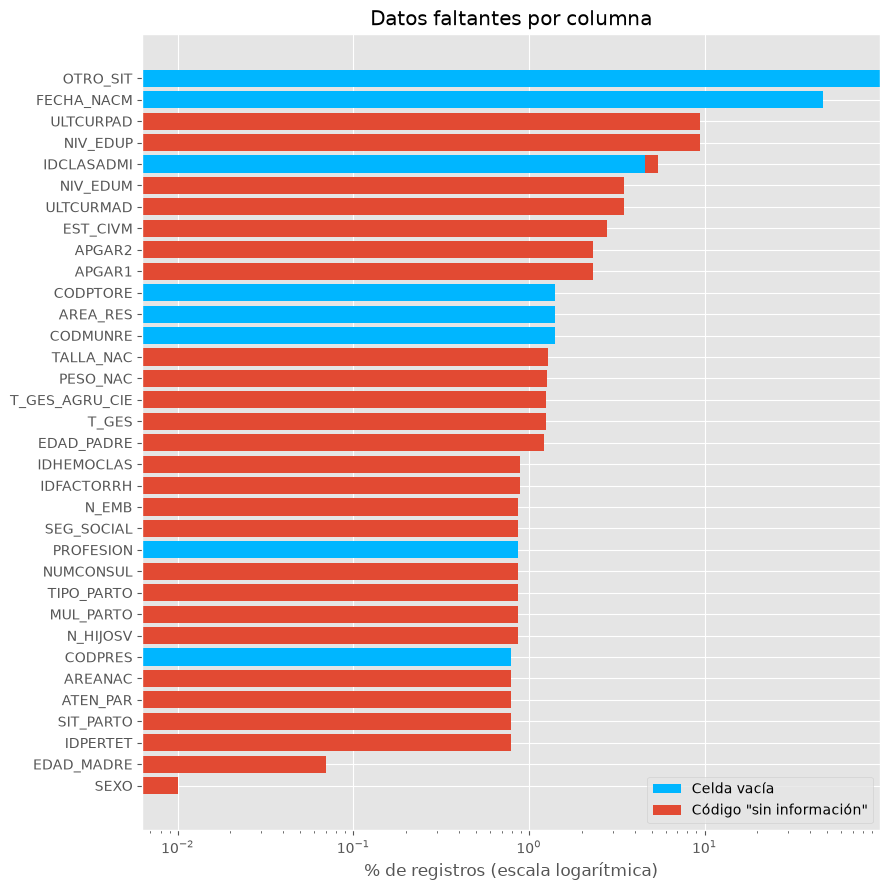

In [6]:
top = calidad[calidad['%_faltante_total'] > 0].sort_values('%_faltante_total')
plt.figure(figsize=(9, 9))
plt.barh(top['columna'], top['%_vacio'], label='Celda vacía', color='#00B6FF')
plt.barh(top['columna'], top['%_sin_informacion'], left=top['%_vacio'], label='Código "sin información"', color='#E24A33')
plt.xscale('log')
plt.xlabel('% de registros (escala logarítmica)')
plt.title('Datos faltantes por columna')
plt.legend()
plt.tight_layout()
plt.show()

**Lectura:**
- `OTRO_SIT` (99,8 % vacía) y `FECHA_NACM` (47,3 % vacía) no sirven como predictores. La segunda solo aplica si la madre ya tenía hijos.
- Los datos del padre (`NIV_EDUP`, `ULTCURPAD`) son los más incompletos entre las variables útiles: cerca del 9,4 %.
- El resto de variables tiene menos del 4 % de faltantes. La variable objetivo, `PESO_NAC`, tiene 1,27 % sin información.

### ¿De dónde vienen los registros sin información?

In [7]:
fuente = {'1': 'Certificado RUAF-ND', '2': 'Notificación étnica', '3': 'Recuperación cruce RNEC'}
resumen = df.groupby(df['TIPOFORMULARIO'].map(fuente)).agg(
    registros=('PESO_NAC', 'size'),
    pct_sin_peso=('PESO_NAC', lambda s: round((s == '9').mean() * 100, 1)),
    pct_sin_gestacion=('T_GES_AGRU_CIE', lambda s: round(s.isin(['6', '9']).mean() * 100, 1)),
    pct_sin_seg_social=('SEG_SOCIAL', lambda s: round((s == '9').mean() * 100, 1)),
)
resumen

,registros,pct_sin_peso,pct_sin_gestacion,pct_sin_seg_social
TIPOFORMULARIO,,,,
Certificado RUAF-ND,511063,0.4,0.4,0.0
Notificación étnica,400,48.5,99.8,99.8
Recuperación cruce RNEC,4086,100.0,100.0,100.0


Los faltantes no están repartidos al azar. Los 4.086 registros de **"Recuperación cruce RNEC"** (nacimientos recuperados al cruzar con la Registraduría) y los 400 de notificación étnica casi no traen información clínica: no tienen peso ni semanas de gestación. Estos registros no se pueden usar para el modelo.

### Duplicados

In [8]:
n_dup = df.duplicated().sum()
print('Filas completamente repetidas:', n_dup, f'({n_dup / len(df) * 100:.2f} %)')

# ¿Cuántas de esas filas repetidas son de embarazos múltiples?
dup = df[df.duplicated(keep=False)]
print('Filas involucradas en alguna repetición:', len(dup))
print(dup['MUL_PARTO'].map(etiquetas['MUL_PARTO']).value_counts())

Filas completamente repetidas: 1568 (0.30 %)


Filas involucradas en alguna repetición: 2657
MUL_PARTO
Sin información    1844
Doble               710
Simple               96
Triple                7
Name: count, dtype: int64


Hay 1.568 filas idénticas, pero **no se deben eliminar sin más**, por tres razones:

1. La base no tiene un identificador del nacimiento, así que dos filas iguales no prueban que sea el mismo bebé.
2. La mayoría son registros "sin información" (los recuperados del cruce con la Registraduría, que se parecen entre sí porque casi todo es 9 o 99) y **embarazos dobles**: dos gemelos del mismo sexo y rango de peso generan dos filas idénticas, y son dos nacimientos reales.
3. Con medio millón de registros y variables agrupadas en rangos, es esperable que algunos nacimientos distintos coincidan en todo.

### Columnas con poca información

In [9]:
# Columnas donde un solo valor concentra más del 95 % de los registros
for col in df.columns:
    cnts = df[col].value_counts(dropna=False)
    top_pct = cnts.iloc[0] / len(df)
    if top_pct > 0.95:
        print(f'{col}: {top_pct * 100:.2f} % de los registros tienen el valor "{cnts.index[0]}"')

AREANAC: 97.67 % de los registros tienen el valor "1"
SIT_PARTO: 97.68 % de los registros tienen el valor "1"
OTRO_SIT: 99.80 % de los registros tienen el valor ""
ANO: 100.00 % de los registros tienen el valor "2023"
ATEN_PAR: 97.69 % de los registros tienen el valor "1"
MUL_PARTO: 97.35 % de los registros tienen el valor "1"
CODPRES: 98.59 % de los registros tienen el valor "170"


PROFESION: 98.66 % de los registros tienen el valor "1"
TIPOFORMULARIO: 99.13 % de los registros tienen el valor "1"


Estas columnas casi no varían. `ANO` es constante (todo es 2023) y `CODPRES`, `PROFESION` y `TIPOFORMULARIO` son administrativas. Hay una excepción importante: **`MUL_PARTO`** aparece en la lista porque el 97 % de los embarazos son simples, pero el 3 % restante (dobles y triples) es justo donde se concentra el bajo peso, como se ve más adelante. Una regla automática de "más del 95 % igual" la habría descartado por error.

## 2.4 Variable objetivo: bajo peso al nacer

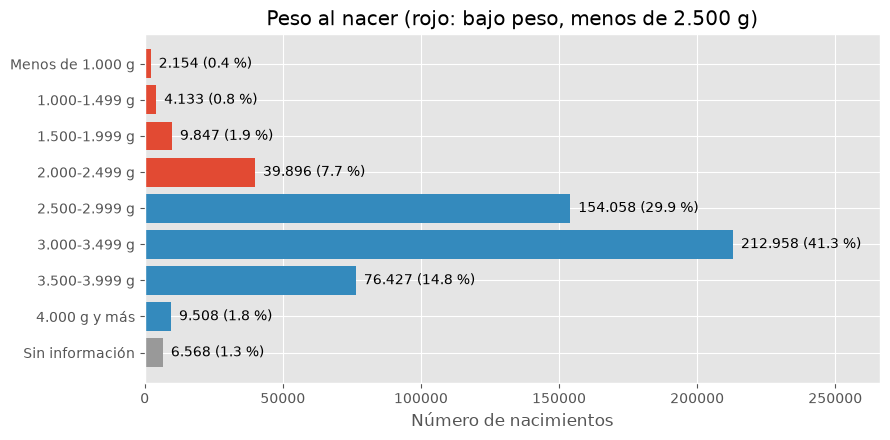

In [10]:
conteo = df['PESO_NAC'].value_counts().sort_index()
colores = ['#E24A33' if c in '1234' else '#348ABD' if c != '9' else '#999999' for c in conteo.index]

plt.figure(figsize=(9, 4.5))
plt.barh([etiquetas['PESO_NAC'][c] for c in conteo.index], conteo.values, color=colores)
for i, v in enumerate(conteo.values):
    plt.text(v, i, f'  {v:,} ({v / len(df) * 100:.1f} %)'.replace(',', '.'), va='center')
plt.xlim(0, conteo.max() * 1.25)
plt.gca().invert_yaxis()
plt.xlabel('Número de nacimientos')
plt.title('Peso al nacer (rojo: bajo peso, menos de 2.500 g)')
plt.tight_layout()
plt.show()

In [11]:
# Se descartan los registros sin peso: no se puede saber a qué clase pertenecen
datos = df[df['PESO_NAC'] != '9'].copy()

# Variable objetivo: 1 = bajo peso (códigos 1 a 4, menos de 2.500 g), 0 = peso de 2.500 g o más
datos['BAJO_PESO'] = datos['PESO_NAC'].isin(['1', '2', '3', '4']).astype(int)

print('Registros con peso conocido:', len(datos))
print('Registros descartados por no tener peso:', len(df) - len(datos))
print()
print(datos['BAJO_PESO'].value_counts().rename({0: 'Peso normal (0)', 1: 'Bajo peso (1)'}))
print(f"\nPorcentaje de bajo peso: {datos['BAJO_PESO'].mean() * 100:.2f} %")

Registros con peso conocido: 508981
Registros descartados por no tener peso: 6568

BAJO_PESO
Peso normal (0)    452951
Bajo peso (1)       56030
Name: count, dtype: int64

Porcentaje de bajo peso: 11.01 %


**Lectura:** de los 508.981 nacimientos con peso conocido, **56.030 (11,0 %) son de bajo peso**. Las clases están **desbalanceadas**: hay unos 8 nacimientos de peso normal por cada uno de bajo peso.

Esto tiene una consecuencia directa para la evaluación: un modelo que respondiera siempre "peso normal" tendría 89 % de exactitud y no detectaría ni un solo caso. Por eso en la fase 5 se usarán *recall*, precisión y matriz de confusión.

## 2.5 Relación de las variables con el bajo peso

Para cada categoría se calcula qué porcentaje de sus nacimientos fue de bajo peso. La línea punteada es el promedio nacional (11,0 %).

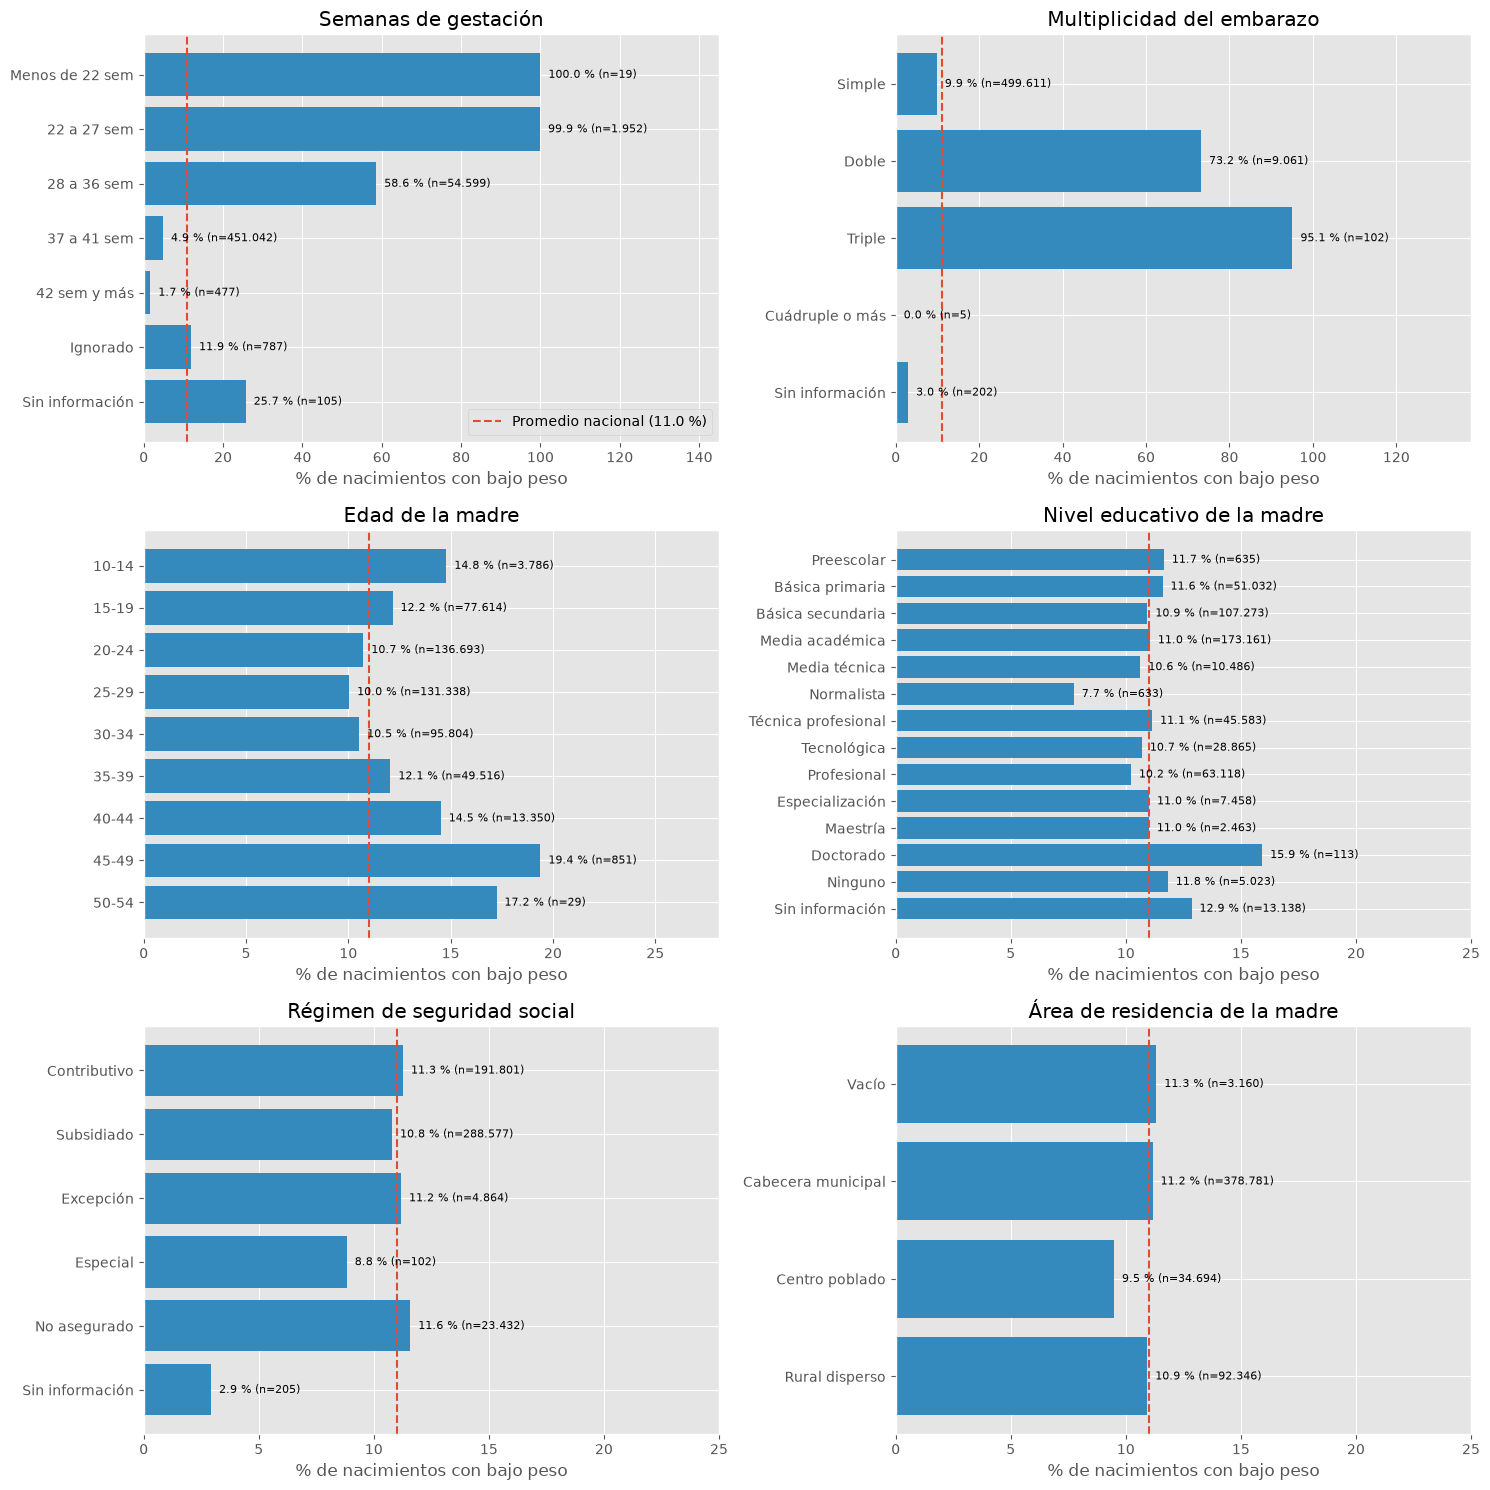

In [12]:
media_global = datos['BAJO_PESO'].mean() * 100

def grafico_bajo_peso(col, titulo, ax):
    """Porcentaje de bajo peso en cada categoría de una variable."""
    t = datos.groupby(col)['BAJO_PESO'].agg(pct='mean', n='size')
    t['pct'] = t['pct'] * 100
    t.index = [etiquetas[col].get(c, c) for c in t.index]
    ax.barh(t.index, t['pct'], color='#348ABD')
    for i, (p, n) in enumerate(zip(t['pct'], t['n'])):
        ax.text(p, i, f'  {p:.1f} % (n={n:,})'.replace(',', '.'), va='center', fontsize=8)
    ax.axvline(media_global, color='#E24A33', linestyle='--', label=f'Promedio nacional ({media_global:.1f} %)')
    ax.set_xlim(0, max(t['pct'].max() * 1.45, 25))
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel('% de nacimientos con bajo peso')
    return t

variables = [('T_GES_AGRU_CIE', 'Semanas de gestación'), ('MUL_PARTO', 'Multiplicidad del embarazo'),
             ('EDAD_MADRE', 'Edad de la madre'), ('NIV_EDUM', 'Nivel educativo de la madre'),
             ('SEG_SOCIAL', 'Régimen de seguridad social'), ('AREA_RES', 'Área de residencia de la madre')]

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
for (col, titulo), ax in zip(variables, axes.ravel()):
    grafico_bajo_peso(col, titulo, ax)
axes[0][0].legend(loc='lower right')
plt.tight_layout()
plt.show()

**Lectura:**
- **Semanas de gestación** es la variable más fuerte: el 58,6 % de los nacidos entre las semanas 28 y 36 tiene bajo peso, frente al 4,9 % de los nacidos a término (37 a 41).
- **Multiplicidad:** 73,2 % de los gemelos y 95,1 % de los trillizos nacen con bajo peso, frente al 9,9 % de los embarazos simples.
- **Edad de la madre:** forma de U. El riesgo es mayor en los extremos (14,8 % entre 10 y 14 años; 19,4 % entre 45 y 49) y menor entre 25 y 29 años (10,0 %).
- **Nivel educativo, seguridad social y área de residencia** casi no cambian el porcentaje. Las categorías con valores llamativos (por ejemplo "Doctorado") tienen muy pocos casos, así que no son concluyentes.

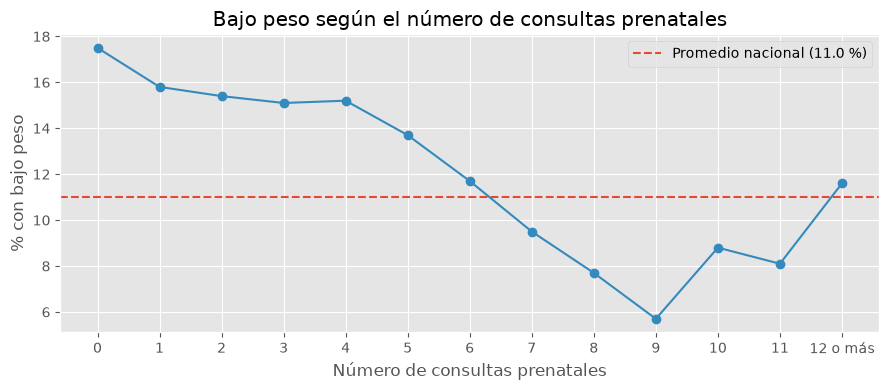

NUMCONSUL,0,1,2,3,4,5,6,7,8,9,10,11,12
pct,17.5,15.8,15.4,15.1,15.2,13.7,11.7,9.5,7.7,5.7,8.8,8.1,11.6
n,15623.0,10574.0,16437.0,25024.0,38889.0,65542.0,75974.0,85603.0,88153.0,43824.0,26072.0,4945.0,12116.0


In [13]:
consultas = pd.to_numeric(datos['NUMCONSUL'])
validas = consultas != 99          # 99 = sin información
t = datos[validas].groupby(consultas[validas].clip(upper=12))['BAJO_PESO'].agg(pct='mean', n='size')
t['pct'] = (t['pct'] * 100).round(1)

plt.figure(figsize=(9, 4))
plt.plot(t.index, t['pct'], marker='o', color='#348ABD')
plt.axhline(media_global, color='#E24A33', linestyle='--', label=f'Promedio nacional ({media_global:.1f} %)')
plt.xticks(t.index, [str(i) if i < 12 else '12 o más' for i in t.index])
plt.xlabel('Número de consultas prenatales')
plt.ylabel('% con bajo peso')
plt.title('Bajo peso según el número de consultas prenatales')
plt.legend()
plt.tight_layout()
plt.show()
t.T

**Lectura:** el bajo peso baja de 17,5 % (sin consultas) a 5,7 % (9 consultas). Hay que interpretarlo con cuidado: un embarazo que termina antes de tiempo también tiene menos semanas para acumular consultas, así que parte de esta relación es reflejo de la prematuridad y no solo del efecto del control prenatal.

## 2.6 Información mutua

La información mutua mide cuánto reduce cada variable la incertidumbre sobre el objetivo, y detecta relaciones que no son lineales (como la forma de U de la edad). Como el objetivo es una categoría, se usa `mutual_info_classif`.

Se separan las variables según **cuándo se conocen**, porque el modelo debe predecir durante el embarazo.

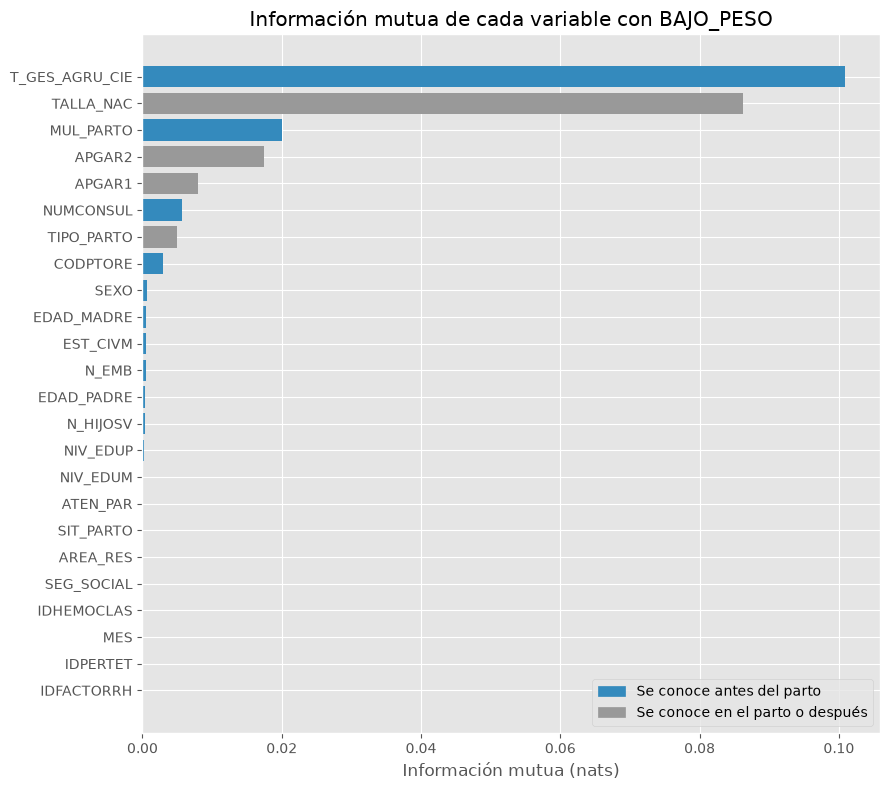

T_GES_AGRU_CIE    0.1009
TALLA_NAC         0.0863
MUL_PARTO         0.0200
APGAR2            0.0175
APGAR1            0.0080
NUMCONSUL         0.0057
TIPO_PARTO        0.0049
CODPTORE          0.0030
SEXO              0.0006
EDAD_MADRE        0.0006
EST_CIVM          0.0005
N_EMB             0.0005
EDAD_PADRE        0.0004
N_HIJOSV          0.0004
NIV_EDUP          0.0002
NIV_EDUM          0.0001
ATEN_PAR          0.0001
SIT_PARTO         0.0001
AREA_RES          0.0001
SEG_SOCIAL        0.0001
IDHEMOCLAS        0.0000
MES               0.0000
IDPERTET          0.0000
IDFACTORRH        0.0000
Name: MI, dtype: float64

In [14]:
antes_del_parto = ['T_GES_AGRU_CIE', 'MUL_PARTO', 'NUMCONSUL', 'EDAD_MADRE', 'EST_CIVM', 'NIV_EDUM',
                   'CODPTORE', 'AREA_RES', 'N_HIJOSV', 'N_EMB', 'SEG_SOCIAL', 'IDPERTET', 'EDAD_PADRE',
                   'NIV_EDUP', 'SEXO', 'MES']
del_parto_o_despues = ['TALLA_NAC', 'APGAR1', 'APGAR2', 'TIPO_PARTO', 'SIT_PARTO', 'ATEN_PAR',
                       'IDHEMOCLAS', 'IDFACTORRH']

# Label encoding: mutual_info_classif necesita números enteros para variables discretas
X = datos[antes_del_parto + del_parto_o_despues].copy()
for col in X.columns:
    X[col], _ = X[col].factorize()
y = datos['BAJO_PESO']

mi = mutual_info_classif(X, y, discrete_features=True, random_state=42)
mi_scores = pd.Series(mi, index=X.columns, name='MI').sort_values()

colores = ['#348ABD' if c in antes_del_parto else '#999999' for c in mi_scores.index]
plt.figure(figsize=(9, 8))
plt.barh(mi_scores.index, mi_scores.values, color=colores)
plt.title('Información mutua de cada variable con BAJO_PESO')
plt.xlabel('Información mutua (nats)')
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#348ABD'), plt.Rectangle((0, 0), 1, 1, color='#999999')],
           labels=['Se conoce antes del parto', 'Se conoce en el parto o después'], loc='lower right')
plt.tight_layout()
plt.show()
mi_scores.sort_values(ascending=False).round(4)

**Lectura:**
- `T_GES_AGRU_CIE` domina (0,10), seguida muy de lejos por `MUL_PARTO` (0,02) y `NUMCONSUL` (0,006). Las demás variables previas al parto aportan muy poco por sí solas.
- `TALLA_NAC` y los `APGAR` tienen información mutua alta, pero **se miden cuando el bebé ya nació**, igual que el peso. Usarlas sería una *fuga de información*: el modelo tendría métricas excelentes y no serviría para anticipar nada. Quedan fuera.
- La información mutua evalúa cada variable por separado y no detecta combinaciones entre variables, así que un valor bajo no obliga a descartar la variable. La decisión final se toma en la fase 3.

## 2.7 El Meta frente al resto del país

Nacimientos de madres residentes en el Meta (con peso conocido): 12844
Porcentaje de bajo peso en el Meta: 6.60 %
Porcentaje de bajo peso nacional:   11.01 %


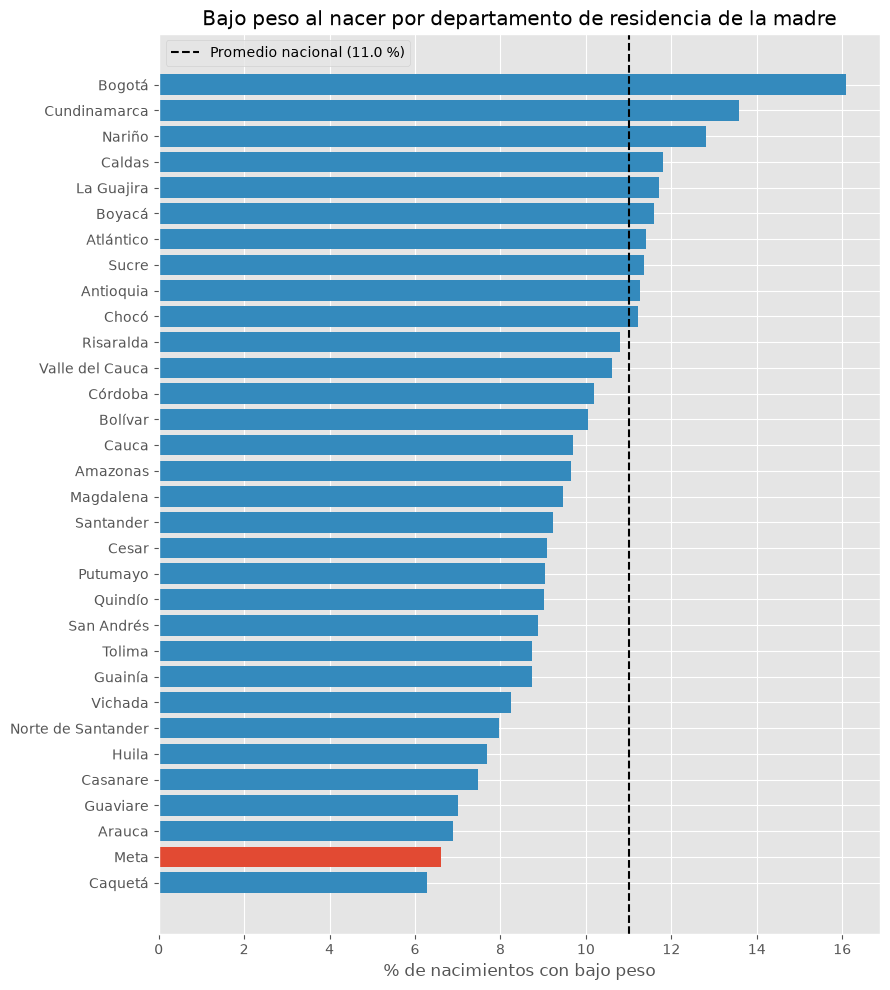

In [15]:
por_dpto = datos[datos['CODPTORE'] != ''].groupby('CODPTORE')['BAJO_PESO'].agg(pct='mean', n='size')
por_dpto['pct'] = por_dpto['pct'] * 100
por_dpto.index = [departamentos.get(c, c) for c in por_dpto.index]
por_dpto = por_dpto[por_dpto['n'] >= 500].sort_values('pct')   # se omiten grupos muy pequeños

print('Nacimientos de madres residentes en el Meta (con peso conocido):', int(por_dpto.loc['Meta', 'n']))
print(f"Porcentaje de bajo peso en el Meta: {por_dpto.loc['Meta', 'pct']:.2f} %")
print(f'Porcentaje de bajo peso nacional:   {media_global:.2f} %')

colores = ['#E24A33' if d == 'Meta' else '#348ABD' for d in por_dpto.index]
plt.figure(figsize=(9, 10))
plt.barh(por_dpto.index, por_dpto['pct'], color=colores)
plt.axvline(media_global, color='black', linestyle='--', label=f'Promedio nacional ({media_global:.1f} %)')
plt.xlabel('% de nacimientos con bajo peso')
plt.title('Bajo peso al nacer por departamento de residencia de la madre')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# ¿La relación con la gestación se mantiene dentro del Meta?
es_meta = datos['CODPTORE'] == '50'
comp = pd.DataFrame({
    'Meta': datos[es_meta].groupby('T_GES_AGRU_CIE')['BAJO_PESO'].mean() * 100,
    'Resto del país': datos[~es_meta].groupby('T_GES_AGRU_CIE')['BAJO_PESO'].mean() * 100,
    'n Meta': datos[es_meta].groupby('T_GES_AGRU_CIE').size(),
}).round(1)
comp.index = [etiquetas['T_GES_AGRU_CIE'][c] for c in comp.index]
comp

,Meta,Resto del país,n Meta
Menos de 22 sem,100.0,100.0,1
22 a 27 sem,100.0,99.9,34
28 a 36 sem,52.1,58.7,975
37 a 41 sem,2.6,4.9,11788
42 sem y más,0.0,1.8,27
Ignorado,23.5,11.7,17
Sin información,0.0,26.2,2


**Lectura:** el Meta tiene **6,6 % de bajo peso, frente al 11,0 % nacional**, y es el segundo departamento con menor porcentaje. Los más altos son Bogotá (16,1 %) y Cundinamarca (13,6 %). El patrón general (los departamentos andinos de mayor altitud arriba; los de la Orinoquía y tierras bajas abajo) es consistente con la relación entre altitud y menor peso al nacer descrita en la literatura, aunque esta base no permite comprobar la causa.

Esto tiene dos consecuencias para el proyecto:
1. La relación con la gestación se mantiene en el Meta (52,1 % de bajo peso en prematuros frente a 2,6 % a término), así que entrenar con datos nacionales sigue siendo razonable.
2. El nivel de riesgo sí cambia según el departamento, incluso a igual tiempo de gestación. Por eso el **departamento de residencia debe entrar como variable del modelo**; de lo contrario, el modelo sobrestimaría el riesgo de las gestantes del Meta.

---
## Conclusiones de la fase 2

1. **Los datos sirven para el objetivo.** Hay 508.981 nacimientos con peso conocido y 11,0 % de bajo peso, con clases desbalanceadas (8 a 1).
2. **La calidad es buena, pero los faltantes están ocultos en códigos** (9, 99, 999) y se concentran en los registros recuperados de la Registraduría.
3. **Pocas variables explican la mayor parte:** semanas de gestación y multiplicidad del embarazo. El resto aporta poco de forma individual.
4. **Hay variables que no pueden usarse** porque se conocen después del nacimiento (talla, APGAR, tipo de parto, hemoclasificación).
5. **El departamento importa:** el riesgo base del Meta es bastante menor que el nacional.

**Pendiente para la fase 3 (preparación):** descartar registros sin peso, decidir el tratamiento de los códigos "sin información", seleccionar las variables finales y codificarlas.

---
# Fase 3. Preparación de los datos

En esta fase se pasa de la base original del DANE a las tablas listas para entrenar los modelos. Cada decisión se apoya en lo encontrado en la fase 2.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

## 3.1 Selección de variables

Se parte de nuevo de la base original (`df`), no de la tabla usada en la exploración de la fase 2.

Se conservan solo las variables que **se conocen antes del parto**, que es cuando la herramienta debe usarse.

| Variable | Descripción | Tipo |
|---|---|---|
| `T_GES_AGRU_CIE` | Semanas de gestación (agrupación CIE) | Categórica |
| `MUL_PARTO` | Embarazo simple, doble, triple | Categórica |
| `NUMCONSUL` | Número de consultas prenatales | Numérica |
| `EDAD_MADRE` | Edad de la madre (grupos de 5 años) | Categórica |
| `EST_CIVM` | Estado conyugal de la madre | Categórica |
| `NIV_EDUM` | Nivel educativo de la madre | Categórica |
| `CODPTORE` | Departamento de residencia de la madre | Categórica |
| `AREA_RES` | Área de residencia de la madre | Categórica |
| `N_HIJOSV` | Hijos nacidos vivos, incluido el presente | Numérica |
| `N_EMB` | Número de embarazos, incluido el presente | Numérica |
| `SEG_SOCIAL` | Régimen de seguridad social | Categórica |
| `IDPERTET` | Pertenencia étnica | Categórica |
| `EDAD_PADRE` | Edad del padre en años | Numérica |
| `NIV_EDUP` | Nivel educativo del padre | Categórica |
| `SEXO` | Sexo del bebé (se conoce por ecografía) | Categórica |

**Variables descartadas y por qué:**
- **Se conocen después del nacimiento** (fuga de información): `TALLA_NAC`, `APGAR1`, `APGAR2`, `IDHEMOCLAS`, `IDFACTORRH`, `TIPO_PARTO`, `SIT_PARTO`, `ATEN_PAR`, `AREANAC`, `COD_DPTO`, `COD_MUNIC`.
- **Casi vacías:** `OTRO_SIT` (99,8 %), `FECHA_NACM` (47,3 %).
- **Constantes o administrativas:** `ANO`, `CODPRES`, `PROFESION`, `TIPOFORMULARIO`.
- **Redundantes:** `T_GES` (misma información que `T_GES_AGRU_CIE`, que usa el corte de 37 semanas con el que se define la prematuridad), `ULTCURMAD` y `ULTCURPAD` (detalle del nivel educativo), `IDCLASADMI` (equivale a `SEG_SOCIAL`).
- **Demasiadas categorías:** `CODMUNRE` (más de 1.000 municipios); se usa el departamento.
- **Sin relación con el objetivo:** `MES` (información mutua de 0,0000 en la fase 2).

In [18]:
categoricas = ['T_GES_AGRU_CIE', 'MUL_PARTO', 'EDAD_MADRE', 'EST_CIVM', 'NIV_EDUM', 'NIV_EDUP',
               'CODPTORE', 'AREA_RES', 'SEG_SOCIAL', 'IDPERTET', 'SEXO']
numericas = ['NUMCONSUL', 'N_HIJOSV', 'N_EMB', 'EDAD_PADRE']

datos = df[categoricas + numericas + ['PESO_NAC']].copy()
print('Variables predictoras seleccionadas:', len(categoricas) + len(numericas))
datos.head()

Variables predictoras seleccionadas: 15


,T_GES_AGRU_CIE,MUL_PARTO,EDAD_MADRE,EST_CIVM,NIV_EDUM,NIV_EDUP,CODPTORE,AREA_RES,SEG_SOCIAL,IDPERTET,SEXO,NUMCONSUL,N_HIJOSV,N_EMB,EDAD_PADRE,PESO_NAC
0,4,1,5,9,99,99,23,3,2,6,1,00,2,2,44,8
1,4,1,6,6,11,11,11,1,1,6,2,10,1,1,35,6
2,4,1,5,6,11,09,11,1,1,6,1,10,1,1,32,6
3,4,1,5,6,10,09,11,1,1,6,1,10,1,1,34,6
4,4,1,5,6,10,10,11,1,1,6,1,12,2,2,37,6


## 3.2 Limpieza de registros

Se eliminan los registros que no se pueden usar. Se lleva la cuenta de cuántos salen en cada paso.

In [19]:
registro = [('Base original', len(datos))]

# 1. Sin peso registrado: no se puede construir la variable objetivo
datos = datos[datos['PESO_NAC'] != '9']
registro.append(('Sin peso al nacer', len(datos)))

# 2. Madres residentes en el exterior: no tienen departamento de residencia en Colombia
datos = datos[datos['CODPTORE'] != '']
registro.append(('Madre residente en el exterior', len(datos)))

# 3. Tiempo de gestación ignorado o sin información (es el predictor principal: no se imputa)
datos = datos[~datos['T_GES_AGRU_CIE'].isin(['6', '9'])]
registro.append(('Sin tiempo de gestación', len(datos)))

# 4. Sexo indeterminado
datos = datos[datos['SEXO'] != '3']
registro.append(('Sexo indeterminado', len(datos)))

# 5. Registros sin información del embarazo (multiplicidad, consultas, hijos, embarazos, seguridad social)
sin_embarazo = ((datos['MUL_PARTO'] == '9') | (datos['NUMCONSUL'] == '99') | (datos['N_HIJOSV'] == '99')
                | (datos['N_EMB'] == '99') | (datos['SEG_SOCIAL'] == '9'))
datos = datos[~sin_embarazo]
registro.append(('Sin información del embarazo', len(datos)))

log = pd.DataFrame(registro, columns=['Paso', 'Registros restantes'])
log['Eliminados'] = (-log['Registros restantes'].diff()).fillna(0).astype(int)
print(f"Se conserva el {len(datos) / len(df) * 100:.2f} % de la base original")
log

Se conserva el 97.93 % de la base original


,Paso,Registros restantes,Eliminados
0,Base original,515549,0
1,Sin peso al nacer,508981,6568
2,Madre residente en el exterior,505821,3160
3,Sin tiempo de gestación,504931,890
4,Sexo indeterminado,504895,36
5,Sin información del embarazo,504889,6


**Lectura:** se conserva el **97,9 %** de la base (504.889 de 515.549 registros). Casi todo lo eliminado son registros sin peso, que no sirven porque no se puede saber a qué clase pertenecen.

El tiempo de gestación faltante **no se imputa** aunque son pocos casos: es el predictor más importante, e inventarle un valor a esos registros metería ruido justo en la variable que más pesa.

**Duplicados:** no se eliminan, por lo discutido en la fase 2 (la base no tiene identificador y los gemelos generan filas idénticas legítimas).

## 3.3 Variable objetivo

In [20]:
datos['BAJO_PESO'] = datos['PESO_NAC'].isin(['1', '2', '3', '4']).astype(int)
datos = datos.drop(columns='PESO_NAC')

print(datos['BAJO_PESO'].value_counts())
print(f"\nPorcentaje de bajo peso: {datos['BAJO_PESO'].mean() * 100:.2f} %")

BAJO_PESO
0    449359
1     55530
Name: count, dtype: int64

Porcentaje de bajo peso: 11.00 %


El porcentaje de bajo peso se mantiene en 11,0 % después de la limpieza, así que los filtros no alteraron la distribución del objetivo.

## 3.4 Datos faltantes

Los códigos "sin información" (9, 99, 999) se convierten en `NaN` para poder tratarlos con las herramientas de pandas y scikit-learn.

In [21]:
for col in numericas:
    datos[col] = pd.to_numeric(datos[col])

datos['EDAD_PADRE'] = datos['EDAD_PADRE'].replace(999, np.nan)
datos['EST_CIVM'] = datos['EST_CIVM'].replace('9', np.nan)
datos['NIV_EDUM'] = datos['NIV_EDUM'].replace('99', np.nan)
datos['NIV_EDUP'] = datos['NIV_EDUP'].replace('99', np.nan)

faltantes = pd.DataFrame({'faltantes': datos.isna().sum(), '%': (datos.isna().mean() * 100).round(2)})
faltantes[faltantes['faltantes'] > 0]

,faltantes,%
EST_CIVM,9353,1.85
NIV_EDUM,12556,2.49
NIV_EDUP,42443,8.41
EDAD_PADRE,1635,0.32


In [22]:
# ¿Los registros con dato faltante se parecen al resto?
print(f"Bajo peso en toda la base: {datos['BAJO_PESO'].mean() * 100:.1f} %")
for col in ['EST_CIVM', 'NIV_EDUM', 'NIV_EDUP', 'EDAD_PADRE']:
    pct = datos.loc[datos[col].isna(), 'BAJO_PESO'].mean() * 100
    print(f'Bajo peso cuando falta {col}: {pct:.1f} %')

Bajo peso en toda la base: 11.0 %
Bajo peso cuando falta EST_CIVM: 12.9 %
Bajo peso cuando falta NIV_EDUM: 13.0 %
Bajo peso cuando falta NIV_EDUP: 12.8 %
Bajo peso cuando falta EDAD_PADRE: 16.1 %


**Decisión de tratamiento:**

| Variable | % faltante | Tratamiento | Razón |
|---|---|---|---|
| `EDAD_PADRE` | 0,32 % | Imputar con la **mediana** | Pocos casos; la mediana no se afecta por valores extremos |
| `EST_CIVM` | 1,85 % | Imputar con la **moda** | Pocos casos; variable categórica |
| `NIV_EDUM` | 2,49 % | Imputar con la **moda** | Pocos casos; variable categórica |
| `NIV_EDUP` | 8,41 % | Categoría propia **"Sin información"** | Demasiados casos para imputar: asignarle "Media" a 42.000 padres distorsionaría la variable |

**Limitación a tener presente:** los registros con datos faltantes tienen un porcentaje de bajo peso algo mayor que el promedio (entre 12,8 % y 16,1 %, frente a 11,0 %). Es decir, la falta de información no es totalmente al azar. Al imputar con moda o mediana esa señal se pierde en las tres variables imputadas; se acepta porque afecta a menos del 3 % de los registros.

La imputación se aplica más adelante, **después de separar entrenamiento y prueba**, para que la moda y la mediana se calculen solo con los datos de entrenamiento.

## 3.5 Valores atípicos

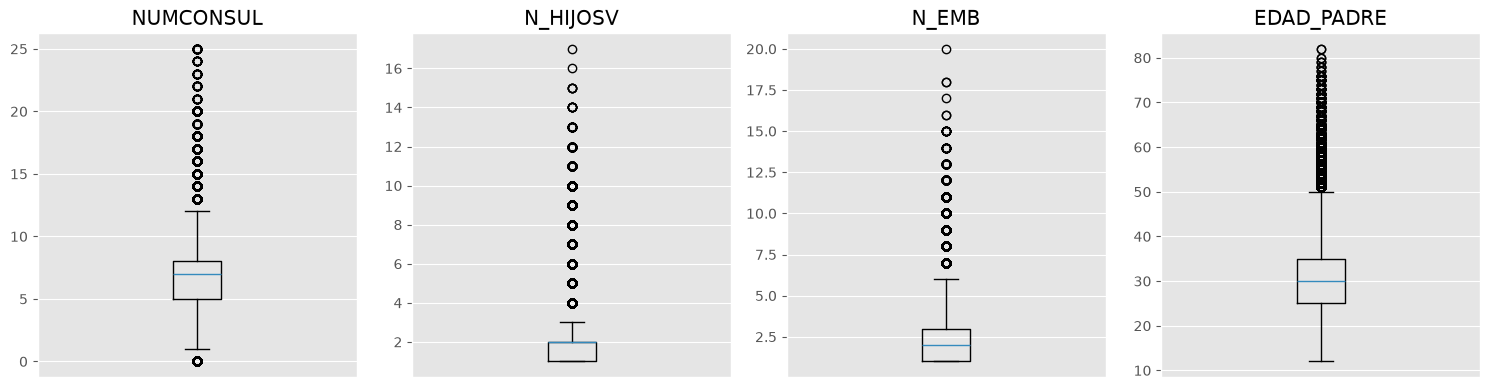

,variable,mínimo,mediana,máximo,límite superior IQR,% sobre el límite
0,NUMCONSUL,0.0,7.0,25.0,12.5,1.18
1,N_HIJOSV,1.0,2.0,17.0,3.5,7.47
2,N_EMB,1.0,2.0,20.0,6.0,1.14
3,EDAD_PADRE,12.0,30.0,82.0,50.0,1.53


In [23]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
filas = []
for col, ax in zip(numericas, axes):
    serie = datos[col].dropna()
    ax.boxplot(serie)
    ax.set_title(col)
    ax.set_xticks([])
    q1, q3 = serie.quantile([0.25, 0.75])
    lim_sup = q3 + 1.5 * (q3 - q1)
    filas.append({'variable': col, 'mínimo': serie.min(), 'mediana': serie.median(), 'máximo': serie.max(),
                  'límite superior IQR': lim_sup, '% sobre el límite': round((serie > lim_sup).mean() * 100, 2)})
plt.tight_layout()
plt.show()
pd.DataFrame(filas)

**Decisión: no se eliminan ni se modifican.** El criterio del rango intercuartílico marca como atípicos hasta el 7,5 % de los registros en `N_HIJOSV`, pero al revisar los valores, todos son **posibles en la realidad**: hasta 25 consultas prenatales, 17 hijos, 20 embarazos o un padre de 82 años. No son errores de digitación.

El IQR marca tantos casos porque estas variables son muy asimétricas (la mayoría de las madres tiene 1 o 2 hijos), no porque haya datos malos. Además, una madre con muchos embarazos es justamente un perfil de interés para el problema, así que eliminarla sería quitar información útil.

## 3.6 Recodificación y agrupación de categorías

Se reemplazan los códigos por etiquetas legibles y se agrupan las categorías con muy pocos casos, que no alcanzan para que el modelo aprenda de ellas:

- Gestación: "menos de 22" (19 casos) se une con "22 a 27" → **Menos de 28**.
- Multiplicidad: "cuádruple o más" (5 casos) se une con "triple" → **Triple o más**.
- Edad de la madre: "50-54" (menos de 50 casos) se une con "45-49" → **45 o más**.
- Estado conyugal: separada y viuda → **Separada o viuda**.
- Educación (madre y padre): 13 niveles se resumen en 7.
- Seguridad social: excepción y especial → **Excepción o especial**.
- Pertenencia étnica: Rom, raizal y palenquero (menos de 400 casos en total) → **Otro grupo étnico**.

In [24]:
educacion = {'13': 'Ninguno o preescolar', '01': 'Ninguno o preescolar', '02': 'Primaria', '03': 'Secundaria',
             '04': 'Media', '05': 'Media', '06': 'Media', '07': 'Técnica o tecnológica',
             '08': 'Técnica o tecnológica', '09': 'Profesional', '10': 'Posgrado', '11': 'Posgrado',
             '12': 'Posgrado'}

recodificacion = {
    'T_GES_AGRU_CIE': {'1': 'Menos de 28', '2': 'Menos de 28', '3': '28 a 36', '4': '37 a 41', '5': '42 o más'},
    'MUL_PARTO': {'1': 'Simple', '2': 'Doble', '3': 'Triple o más', '4': 'Triple o más'},
    'EDAD_MADRE': {'1': '10-14', '2': '15-19', '3': '20-24', '4': '25-29', '5': '30-34', '6': '35-39',
                   '7': '40-44', '8': '45 o más', '9': '45 o más'},
    'EST_CIVM': {'1': 'Unión libre 2 años o más', '2': 'Unión libre menos de 2 años',
                 '3': 'Separada o viuda', '4': 'Separada o viuda', '5': 'Soltera', '6': 'Casada'},
    'NIV_EDUM': educacion,
    'NIV_EDUP': educacion,
    'CODPTORE': departamentos,
    'AREA_RES': {'1': 'Cabecera municipal', '2': 'Centro poblado', '3': 'Rural disperso'},
    'SEG_SOCIAL': {'1': 'Contributivo', '2': 'Subsidiado', '3': 'Excepción o especial',
                   '4': 'Excepción o especial', '5': 'No asegurado'},
    'IDPERTET': {'1': 'Indígena', '2': 'Otro grupo étnico', '3': 'Otro grupo étnico',
                 '4': 'Otro grupo étnico', '5': 'Afrodescendiente', '6': 'Ninguno'},
    'SEXO': {'1': 'Masculino', '2': 'Femenino'},
}

for col, mapa in recodificacion.items():
    antes = datos[col].isna().sum()
    datos[col] = datos[col].map(mapa)
    # Verificación: ningún código quedó sin etiqueta
    assert datos[col].isna().sum() == antes, f'Hay códigos sin etiqueta en {col}'

datos = datos.rename(columns={'CODPTORE': 'DEPARTAMENTO'})
categoricas = ['DEPARTAMENTO' if c == 'CODPTORE' else c for c in categoricas]

for col in categoricas:
    print(f'{col}: {datos[col].nunique()} categorías')
datos.head()

T_GES_AGRU_CIE: 4 categorías
MUL_PARTO: 3 categorías
EDAD_MADRE: 8 categorías
EST_CIVM: 5 categorías
NIV_EDUM: 7 categorías
NIV_EDUP: 7 categorías
DEPARTAMENTO: 33 categorías
AREA_RES: 3 categorías
SEG_SOCIAL: 4 categorías
IDPERTET: 4 categorías
SEXO: 2 categorías


,T_GES_AGRU_CIE,MUL_PARTO,EDAD_MADRE,EST_CIVM,NIV_EDUM,NIV_EDUP,DEPARTAMENTO,AREA_RES,SEG_SOCIAL,IDPERTET,SEXO,NUMCONSUL,N_HIJOSV,N_EMB,EDAD_PADRE,BAJO_PESO
0,37 a 41,Simple,30-34,NaN,NaN,NaN,Córdoba,Rural disperso,Subsidiado,Ninguno,Masculino,0,2,2,44.0,0
1,37 a 41,Simple,35-39,Casada,Posgrado,Posgrado,Bogotá,Cabecera municipal,Contributivo,Ninguno,Femenino,10,1,1,35.0,0
2,37 a 41,Simple,30-34,Casada,Posgrado,Profesional,Bogotá,Cabecera municipal,Contributivo,Ninguno,Masculino,10,1,1,32.0,0
3,37 a 41,Simple,30-34,Casada,Posgrado,Profesional,Bogotá,Cabecera municipal,Contributivo,Ninguno,Masculino,10,1,1,34.0,0
4,37 a 41,Simple,30-34,Casada,Posgrado,Posgrado,Bogotá,Cabecera municipal,Contributivo,Ninguno,Masculino,12,2,2,37.0,0


In [25]:
datos.to_csv('nacimientos_limpio.csv', index=False, encoding='utf-8-sig')
print('Guardado: nacimientos_limpio.csv | dimensiones:', datos.shape)

Guardado: nacimientos_limpio.csv | dimensiones: (504889, 16)


`nacimientos_limpio.csv` es la base limpia en formato legible. Todavía tiene los faltantes como celdas vacías, porque la imputación se hace en el paso siguiente.

## 3.7 Separación en entrenamiento y prueba

Se separa el 80 % para entrenar y el 20 % para evaluar. La separación se hace **antes** de imputar, codificar y escalar, para que el conjunto de prueba no influya en ningún cálculo. Así la evaluación de la fase 5 refleja cómo se comportaría el modelo con nacimientos que nunca ha visto.

In [26]:
X = datos.drop(columns='BAJO_PESO')
y = datos['BAJO_PESO']

# stratify=y mantiene el mismo porcentaje de bajo peso en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Entrenamiento:', X_train.shape, f'| bajo peso: {y_train.mean() * 100:.2f} %')
print('Prueba:       ', X_test.shape, f'| bajo peso: {y_test.mean() * 100:.2f} %')

Entrenamiento: (403911, 15) | bajo peso: 11.00 %
Prueba:        (100978, 15) | bajo peso: 11.00 %


Con `stratify=y` ambos conjuntos quedan con el mismo 11,0 % de bajo peso.

## 3.8 Imputación

`SimpleImputer` aprende la moda y la mediana en entrenamiento (`fit`) y aplica esos mismos valores a la prueba (`transform`).

In [27]:
X_train, X_test = X_train.copy(), X_test.copy()

# Categóricas con pocos faltantes: se imputan con la moda (aprendida solo en entrenamiento)
imp_moda = SimpleImputer(strategy='most_frequent')
X_train[['EST_CIVM', 'NIV_EDUM']] = imp_moda.fit_transform(X_train[['EST_CIVM', 'NIV_EDUM']])
X_test[['EST_CIVM', 'NIV_EDUM']] = imp_moda.transform(X_test[['EST_CIVM', 'NIV_EDUM']])

# Numérica con pocos faltantes: se imputa con la mediana
imp_mediana = SimpleImputer(strategy='median')
X_train[['EDAD_PADRE']] = imp_mediana.fit_transform(X_train[['EDAD_PADRE']])
X_test[['EDAD_PADRE']] = imp_mediana.transform(X_test[['EDAD_PADRE']])

# Educación del padre: demasiados faltantes para imputar; se deja como categoría propia
X_train['NIV_EDUP'] = X_train['NIV_EDUP'].fillna('Sin información')
X_test['NIV_EDUP'] = X_test['NIV_EDUP'].fillna('Sin información')

valores_imputacion = {'EST_CIVM': imp_moda.statistics_[0], 'NIV_EDUM': imp_moda.statistics_[1],
                      'EDAD_PADRE': float(imp_mediana.statistics_[0])}
print('Valores usados para imputar:', valores_imputacion)
print('Faltantes restantes en entrenamiento:', X_train.isna().sum().sum())
print('Faltantes restantes en prueba:       ', X_test.isna().sum().sum())

Valores usados para imputar: {'EST_CIVM': 'Unión libre 2 años o más', 'NIV_EDUM': 'Media', 'EDAD_PADRE': 30.0}


Faltantes restantes en entrenamiento: 0
Faltantes restantes en prueba:        0


## 3.9 Codificación de variables categóricas

Los modelos necesitan números. Se usa **codificación one-hot** (`get_dummies`): cada categoría se convierte en una columna de 0 y 1.

No se usa `LabelEncoder` (un número por categoría) porque le daría un orden falso a variables que no lo tienen: el modelo interpretaría que el departamento 33 es "mayor" que el 1. Tampoco se usa en la edad de la madre, aunque sí tiene orden, porque su relación con el bajo peso tiene forma de U (riesgo alto en los extremos) y la regresión logística no puede representar eso con un solo número.

In [28]:
X_train = pd.get_dummies(X_train, columns=categoricas, dtype='int8')
X_test = pd.get_dummies(X_test, columns=categoricas, dtype='int8')

# La prueba debe tener exactamente las mismas columnas, en el mismo orden, que el entrenamiento
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('Columnas después de codificar:', X_train.shape[1])
print(X_train.columns.tolist())

Columnas después de codificar: 85
['NUMCONSUL', 'N_HIJOSV', 'N_EMB', 'EDAD_PADRE', 'T_GES_AGRU_CIE_28 a 36', 'T_GES_AGRU_CIE_37 a 41', 'T_GES_AGRU_CIE_42 o más', 'T_GES_AGRU_CIE_Menos de 28', 'MUL_PARTO_Doble', 'MUL_PARTO_Simple', 'MUL_PARTO_Triple o más', 'EDAD_MADRE_10-14', 'EDAD_MADRE_15-19', 'EDAD_MADRE_20-24', 'EDAD_MADRE_25-29', 'EDAD_MADRE_30-34', 'EDAD_MADRE_35-39', 'EDAD_MADRE_40-44', 'EDAD_MADRE_45 o más', 'EST_CIVM_Casada', 'EST_CIVM_Separada o viuda', 'EST_CIVM_Soltera', 'EST_CIVM_Unión libre 2 años o más', 'EST_CIVM_Unión libre menos de 2 años', 'NIV_EDUM_Media', 'NIV_EDUM_Ninguno o preescolar', 'NIV_EDUM_Posgrado', 'NIV_EDUM_Primaria', 'NIV_EDUM_Profesional', 'NIV_EDUM_Secundaria', 'NIV_EDUM_Técnica o tecnológica', 'NIV_EDUP_Media', 'NIV_EDUP_Ninguno o preescolar', 'NIV_EDUP_Posgrado', 'NIV_EDUP_Primaria', 'NIV_EDUP_Profesional', 'NIV_EDUP_Secundaria', 'NIV_EDUP_Sin información', 'NIV_EDUP_Técnica o tecnológica', 'DEPARTAMENTO_Amazonas', 'DEPARTAMENTO_Antioquia', 'DEPARTA

## 3.10 Escalado de variables numéricas

Las cuatro variables numéricas se estandarizan (media 0, desviación estándar 1) con `StandardScaler`, ajustado solo con entrenamiento. La regresión logística lo necesita para que ninguna variable pese más solo por estar en una escala mayor (la edad del padre llega a 82; los hijos, a 17). El árbol de decisión no se afecta por la escala, así que puede usar los mismos datos.

In [29]:
escalador = StandardScaler()
X_train[numericas] = escalador.fit_transform(X_train[numericas]).astype('float32')
X_test[numericas] = escalador.transform(X_test[numericas]).astype('float32')

X_train[numericas].describe().round(2)

,NUMCONSUL,N_HIJOSV,N_EMB,EDAD_PADRE
count,403911.00,403911.00,403911.00,403911.00
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.42,-0.77,-0.82,-2.37
25%,-0.53,-0.77,-0.82,-0.69
50%,0.23,0.10,-0.06,-0.04
75%,0.61,0.10,0.71,0.60
max,7.05,13.19,13.74,6.42


---
## Conclusiones de la fase 3

1. Se seleccionaron **15 variables predictoras**, todas conocidas antes del parto.
2. Se conservó el **97,9 %** de los registros (504.889), sin alterar el porcentaje de bajo peso (11,0 %).
3. Los faltantes se trataron según su magnitud: imputación con moda o mediana cuando eran menos del 3 %, y categoría propia para la educación del padre (8,4 %).
4. Los valores atípicos se conservaron por ser valores reales posibles.
5. El resultado son **85 columnas**: 403.911 registros para entrenamiento y 100.978 para prueba.

**El desbalance de clases (11 % frente a 89 %) no se corrige aquí.** Se manejará en la fase 4 al entrenar los modelos, para no alterar los datos de prueba.

---
# Fase 4. Modelado

Se entrenan dos algoritmos de clasificación sobre los mismos datos:

- **Árbol de decisión:** aprende reglas del tipo "si la gestación fue de menos de 37 semanas y el embarazo es doble, entonces...". Es fácil de interpretar y de dibujar.
- **Regresión logística:** calcula una probabilidad de bajo peso sumando el aporte de cada variable. Sirve como modelo de comparación.

**Manejo del desbalance.** Solo el 11 % de los nacimientos es de bajo peso. Sin corrección, los modelos aprenden a favorecer la clase mayoritaria. Se usa `class_weight='balanced'`, que le da más peso a los errores cometidos en la clase minoritaria, sin modificar ni duplicar los datos.

**Conjunto de validación.** Para elegir la configuración de los modelos no se puede usar la prueba, porque dejaría de ser una evaluación imparcial. Por eso se aparta una parte del entrenamiento como validación. La prueba queda reservada para la fase 5.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

In [31]:
X_ent, X_val, y_ent, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

print('Entrenamiento:', X_ent.shape)
print('Validación:   ', X_val.shape)
print('Prueba (no se toca hasta la fase 5):', X_test.shape)

Entrenamiento: (323128, 85)
Validación:    (80783, 85)
Prueba (no se toca hasta la fase 5): (100978, 85)


## 4.1 Métricas

- **Exactitud:** porcentaje total de aciertos. Engañosa con clases desbalanceadas.
- **Recall:** de los bebés que sí nacieron con bajo peso, qué proporción detectó el modelo. Es la métrica prioritaria según el criterio de éxito de la fase 1.
- **Precisión:** de los casos que el modelo marcó como bajo peso, qué proporción lo era realmente.
- **F1:** combina recall y precisión en un solo número.
- **AUC:** mide qué tan bien el modelo ordena los casos de mayor a menor riesgo, sin depender de un punto de corte. 0,5 equivale a adivinar al azar y 1,0 es perfecto.

In [32]:
def metricas(modelo, X, y):
    """Métricas de un modelo sobre un conjunto de datos."""
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    return {'exactitud': round(accuracy_score(y, pred), 3),
            'recall': round(recall_score(y, pred), 3),
            'precisión': round(precision_score(y, pred, zero_division=0), 3),
            'F1': round(f1_score(y, pred), 3),
            'AUC': round(roc_auc_score(y, prob), 3)}

## 4.2 Línea base

In [33]:
# strategy='most_frequent': predice siempre la clase más frecuente ("peso normal")
linea_base = DummyClassifier(strategy='most_frequent').fit(X_ent, y_ent)
resultados = {'Línea base (siempre "peso normal")': metricas(linea_base, X_val, y_val)}
pd.DataFrame(resultados).T

,exactitud,recall,precisión,F1,AUC
"Línea base (siempre ""peso normal"")",0.89,0.0,0.0,0.0,0.5


La línea base tiene **89 % de exactitud y 0 % de recall**: acierta casi siempre y no detecta ningún caso de bajo peso. Es el punto de referencia que los modelos deben superar, y confirma que la exactitud no sirve como criterio.

## 4.3 Árbol de decisión

El parámetro principal del árbol es su **profundidad máxima**. Un árbol muy corto no capta los patrones; uno muy profundo memoriza los datos de entrenamiento y falla con datos nuevos (sobreajuste). Se prueban varias profundidades y se compara el resultado en entrenamiento y en validación.

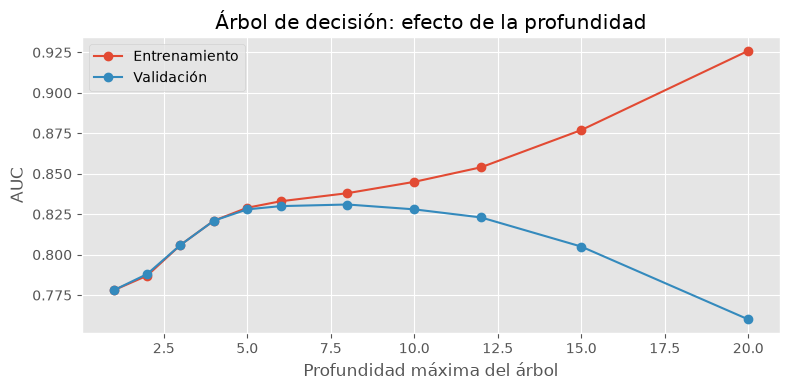

,profundidad,hojas,AUC entrenamiento,AUC validación,recall validación,precisión validación
0,1,2,0.778,0.778,0.607,0.592
1,2,4,0.787,0.788,0.629,0.588
2,3,8,0.806,0.806,0.629,0.588
3,4,15,0.821,0.821,0.629,0.588
4,5,29,0.829,0.828,0.628,0.588
5,6,52,0.833,0.830,0.659,0.490
6,8,151,0.838,0.831,0.666,0.469
7,10,401,0.845,0.828,0.659,0.471
8,12,998,0.854,0.823,0.655,0.460
9,15,3048,0.877,0.805,0.662,0.413


In [34]:
filas = []
for prof in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
    arbol = DecisionTreeClassifier(max_depth=prof, class_weight='balanced', random_state=42).fit(X_ent, y_ent)
    filas.append({'profundidad': prof, 'hojas': arbol.get_n_leaves(),
                  'AUC entrenamiento': metricas(arbol, X_ent, y_ent)['AUC'],
                  'AUC validación': metricas(arbol, X_val, y_val)['AUC'],
                  'recall validación': metricas(arbol, X_val, y_val)['recall'],
                  'precisión validación': metricas(arbol, X_val, y_val)['precisión']})
prueba_prof = pd.DataFrame(filas)

plt.figure(figsize=(8, 4))
plt.plot(prueba_prof['profundidad'], prueba_prof['AUC entrenamiento'], marker='o', label='Entrenamiento')
plt.plot(prueba_prof['profundidad'], prueba_prof['AUC validación'], marker='o', label='Validación')
plt.xlabel('Profundidad máxima del árbol')
plt.ylabel('AUC')
plt.title('Árbol de decisión: efecto de la profundidad')
plt.legend()
plt.tight_layout()
plt.show()
prueba_prof

**Lectura:** hasta una profundidad de 6 a 8, las curvas de entrenamiento y validación van juntas. A partir de ahí se separan: el AUC de entrenamiento sigue subiendo (0,93 con profundidad 20) mientras el de validación cae (0,76). Eso es **sobreajuste**.

Se elige **profundidad 6**. La profundidad 8 es apenas mejor en validación (0,831 frente a 0,830), pero necesita 151 hojas en lugar de 52. Ante resultados casi iguales se prefiere el modelo más simple, que además es más fácil de explicar.

In [35]:
arbol = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42).fit(X_ent, y_ent)
resultados['Árbol de decisión'] = metricas(arbol, X_val, y_val)

# Para comparar: el mismo árbol sin compensar el desbalance de clases
arbol_sin_balancear = DecisionTreeClassifier(max_depth=6, random_state=42).fit(X_ent, y_ent)

pd.DataFrame({'Árbol con class_weight="balanced"': metricas(arbol, X_val, y_val),
              'Árbol sin balancear': metricas(arbol_sin_balancear, X_val, y_val)}).T

,exactitud,recall,precisión,F1,AUC
"Árbol con class_weight=""balanced""",0.887,0.659,0.490,0.562,0.830
Árbol sin balancear,0.913,0.493,0.633,0.554,0.831


**Efecto del balanceo:** sin `class_weight='balanced'`, el árbol detecta solo el 49 % de los casos de bajo peso; con el balanceo, el 66 %. A cambio baja la precisión (de 63 % a 49 %), es decir, hay más falsas alarmas. Para este problema ese intercambio es el deseado, porque es más grave no detectar un embarazo de riesgo que revisar uno de más.

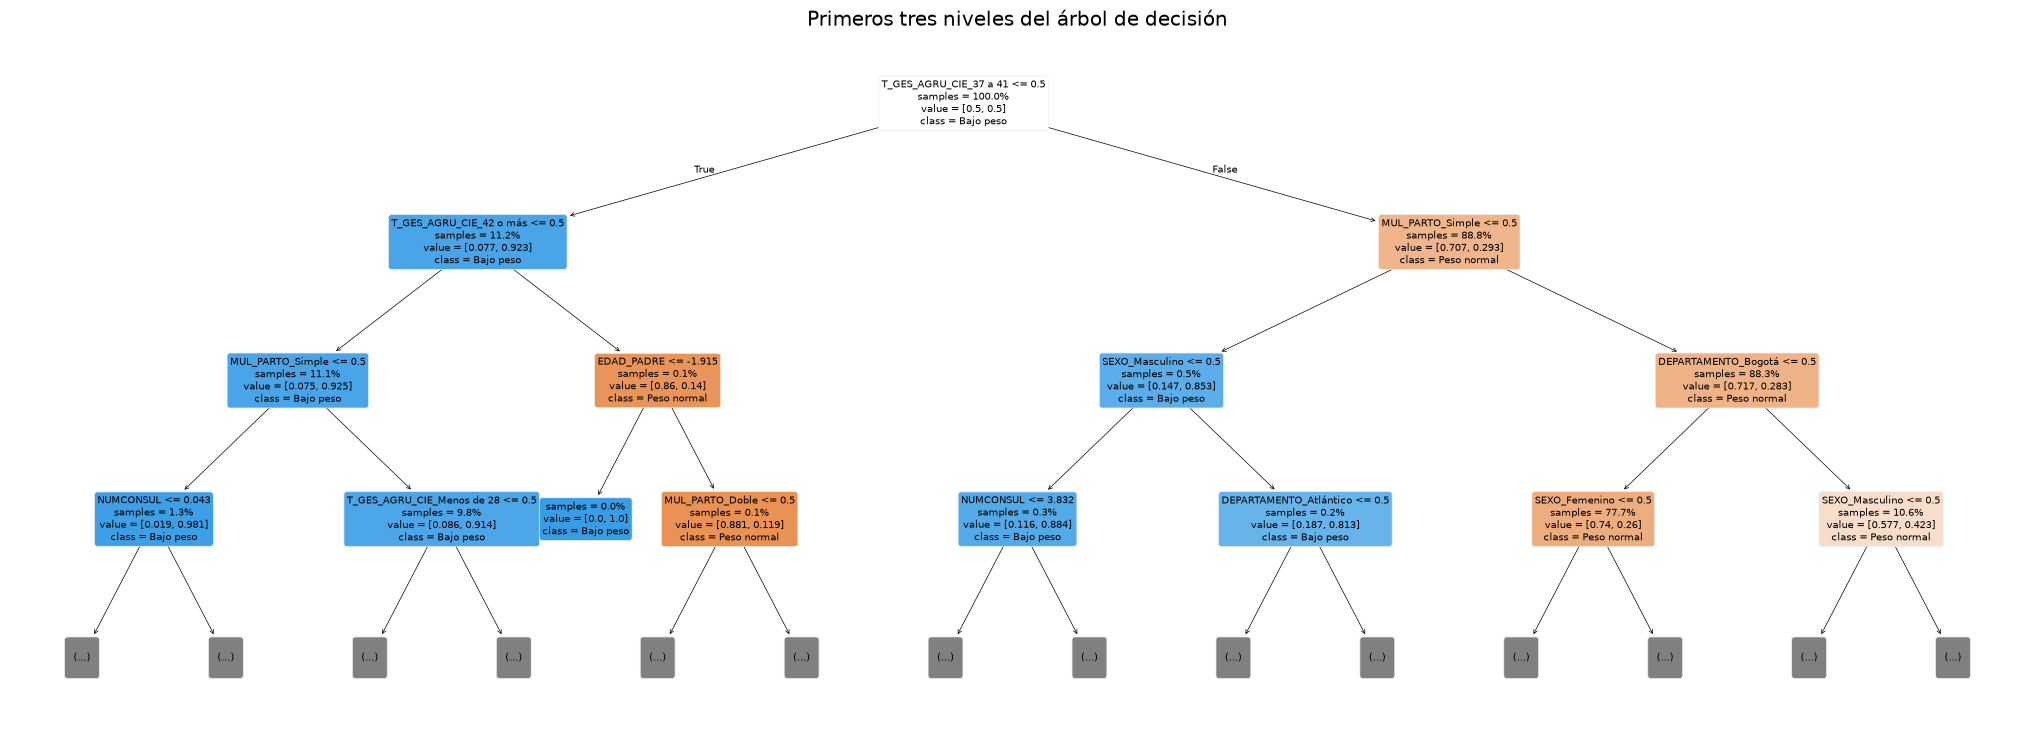

In [36]:
plt.figure(figsize=(26, 9))
plot_tree(arbol, max_depth=3, feature_names=X_ent.columns, class_names=['Peso normal', 'Bajo peso'],
          filled=True, rounded=True, proportion=True, impurity=False, fontsize=7)
plt.title('Primeros tres niveles del árbol de decisión')
plt.show()

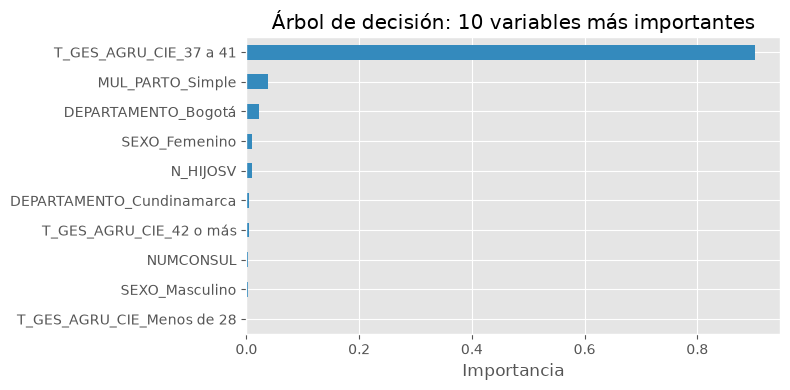

T_GES_AGRU_CIE_37 a 41        0.9016
MUL_PARTO_Simple              0.0389
DEPARTAMENTO_Bogotá           0.0229
SEXO_Femenino                 0.0100
N_HIJOSV                      0.0092
DEPARTAMENTO_Cundinamarca     0.0038
T_GES_AGRU_CIE_42 o más       0.0038
NUMCONSUL                     0.0034
SEXO_Masculino                0.0025
T_GES_AGRU_CIE_Menos de 28    0.0012
dtype: float64

In [37]:
importancia = pd.Series(arbol.feature_importances_, index=X_ent.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importancia.head(10).sort_values().plot.barh(color='#348ABD')
plt.title('Árbol de decisión: 10 variables más importantes')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()
importancia.head(10).round(4)

**Lectura del árbol:** la primera pregunta que hace es si el bebé nació a término (37 a 41 semanas). Después separa por multiplicidad del embarazo, y más abajo aparecen el departamento (Bogotá) y el sexo del bebé. Las semanas de gestación concentran casi toda la importancia, lo que coincide con la información mutua de la fase 2.

En el dibujo, `samples` es el porcentaje de registros que llega a cada nodo y `value` es la proporción de cada clase **ya ponderada por el balanceo**; por eso el nodo inicial muestra [0.5, 0.5] y no [0.89, 0.11].

Las variables numéricas aparecen en el árbol con valores estandarizados (por ejemplo, `EDAD_PADRE <= -1.92`), porque se escalaron en la fase 3.

## 4.4 Regresión logística

In [38]:
logistica = LogisticRegression(class_weight='balanced', max_iter=1000).fit(X_ent, y_ent)
resultados['Regresión logística'] = metricas(logistica, X_val, y_val)
pd.DataFrame(resultados).T

,exactitud,recall,precisión,F1,AUC
"Línea base (siempre ""peso normal"")",0.890,0.000,0.000,0.000,0.500
Árbol de decisión,0.887,0.659,0.490,0.562,0.830
Regresión logística,0.897,0.650,0.524,0.580,0.841


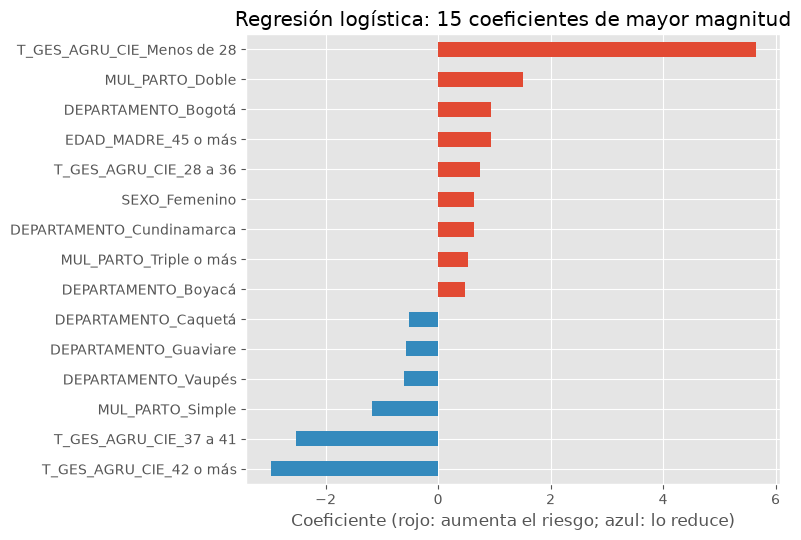

T_GES_AGRU_CIE_Menos de 28    5.648
T_GES_AGRU_CIE_42 o más      -2.976
T_GES_AGRU_CIE_37 a 41       -2.535
MUL_PARTO_Doble               1.506
MUL_PARTO_Simple             -1.169
DEPARTAMENTO_Bogotá           0.945
EDAD_MADRE_45 o más           0.934
T_GES_AGRU_CIE_28 a 36        0.740
SEXO_Femenino                 0.645
DEPARTAMENTO_Cundinamarca     0.643
DEPARTAMENTO_Vaupés          -0.608
DEPARTAMENTO_Guaviare        -0.565
MUL_PARTO_Triple o más        0.540
DEPARTAMENTO_Caquetá         -0.519
DEPARTAMENTO_Boyacá           0.484
dtype: float64

In [39]:
coeficientes = pd.Series(logistica.coef_[0], index=X_ent.columns)
mayores = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 5.5))
mayores.sort_values().plot.barh(color=['#E24A33' if v > 0 else '#348ABD' for v in mayores.sort_values()])
plt.title('Regresión logística: 15 coeficientes de mayor magnitud')
plt.xlabel('Coeficiente (rojo: aumenta el riesgo; azul: lo reduce)')
plt.tight_layout()
plt.show()
mayores.round(3)

**Lectura:** la regresión logística obtiene resultados muy parecidos a los del árbol, con un AUC algo mayor (0,841 frente a 0,830) y mejor precisión (52 % frente a 49 %) con un recall similar (65 % frente a 66 %).

Los coeficientes cuentan la misma historia que el árbol: la gestación de menos de 28 semanas es el factor que más aumenta el riesgo, seguida del embarazo doble. Entre los departamentos, **Bogotá, Cundinamarca y Boyacá aumentan el riesgo**, mientras que Caquetá, Guaviare y Vaupés lo reducen, lo que coincide con el patrón de altitud observado en la fase 2. El sexo femenino también se asocia con mayor probabilidad de bajo peso.

Los coeficientes deben leerse como aportes relativos dentro de cada variable, no como efectos causales.

## 4.5 Experimento: ¿qué pasa sin las semanas de gestación?

Las semanas de gestación dominan el modelo, pero al inicio del embarazo todavía no se sabe si el parto será prematuro. Este experimento mide cuánto se puede predecir solo con las demás variables.

In [40]:
cols_sin_gestacion = [c for c in X_ent.columns if not c.startswith('T_GES_AGRU_CIE')]

arbol_sg = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42).fit(X_ent[cols_sin_gestacion], y_ent)
logistica_sg = LogisticRegression(class_weight='balanced', max_iter=1000).fit(X_ent[cols_sin_gestacion], y_ent)

resultados['Árbol sin gestación'] = metricas(arbol_sg, X_val[cols_sin_gestacion], y_val)
resultados['Logística sin gestación'] = metricas(logistica_sg, X_val[cols_sin_gestacion], y_val)
pd.DataFrame(resultados).T

,exactitud,recall,precisión,F1,AUC
"Línea base (siempre ""peso normal"")",0.890,0.000,0.000,0.000,0.500
Árbol de decisión,0.887,0.659,0.490,0.562,0.830
Regresión logística,0.897,0.650,0.524,0.580,0.841
Árbol sin gestación,0.568,0.666,0.156,0.253,0.664
Logística sin gestación,0.685,0.561,0.188,0.281,0.684


In [41]:
# ¿Cuántos de los casos de bajo peso ocurren en bebés nacidos a término?
bajo = datos[datos['BAJO_PESO'] == 1]
(bajo['T_GES_AGRU_CIE'].value_counts(normalize=True) * 100).round(1)

T_GES_AGRU_CIE
28 a 36        57.2
37 a 41        39.3
Menos de 28     3.5
42 o más        0.0
Name: proportion, dtype: float64

**Lectura:** sin las semanas de gestación el AUC cae de 0,84 a 0,68 y la precisión a menos del 19 %: de cada 100 alertas, más de 80 serían falsas. **Las características de la madre, por sí solas, predicen poco el bajo peso.**

La última tabla explica además por qué el recall no pasa de 66 % ni siquiera con la gestación: el **39 % de los bebés con bajo peso nació a término**. Esos casos no se distinguen por la prematuridad, y el certificado de nacido vivo no trae las variables clínicas que los explicarían (nutrición de la madre, hipertensión, tabaquismo).

Este es un resultado del proyecto, no un defecto: muestra el límite de lo que se puede predecir con datos administrativos.

## 4.6 Modelos finales

In [42]:
# Los dos modelos elegidos se reentrenan con todo el conjunto de entrenamiento
modelo_arbol = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42).fit(X_train, y_train)
modelo_logistica = LogisticRegression(class_weight='balanced', max_iter=1000).fit(X_train, y_train)
print('Modelos finales entrenados con', len(X_train), 'registros')

Modelos finales entrenados con 403911 registros


---
## Conclusiones de la fase 4

1. Ambos modelos superan ampliamente a la línea base: detectan cerca del **65 % de los casos de bajo peso**, frente al 0 % de predecir siempre "peso normal".
2. El **árbol de decisión (profundidad 6)** y la **regresión logística** rinden de forma muy similar en validación; la logística es ligeramente mejor en AUC y precisión.
3. El balanceo de clases sube el recall del árbol de 49 % a 66 %, a costa de más falsas alarmas.
4. Las semanas de gestación son indispensables: sin ellas el modelo pierde casi toda su utilidad.

**Pendiente para la fase 5 (evaluación):** medir los dos modelos finales en el conjunto de prueba.

---
# Fase 5. Evaluación

Hasta aquí los modelos se compararon con el conjunto de validación. Ahora se miden con el **conjunto de prueba**: 100.978 nacimientos que no se usaron ni para entrenar ni para elegir la configuración. Es la estimación más honesta de cómo se comportarían con casos nuevos.

## 5.1 Criterio de éxito

En la fase 1 se dejó pendiente el valor numérico del criterio. Con los resultados de validación de la fase 4 (recall cercano a 65 % y precisión cercana a 50 %) se fija así, **antes de mirar el conjunto de prueba**:

- **Recall de la clase "bajo peso" de al menos 60 %:** detectar como mínimo 6 de cada 10 casos.
- **Precisión de al menos 45 %:** que cerca de la mitad de las alertas sean correctas, para que la herramienta no sature el seguimiento con falsas alarmas.
- **Superar a la línea base**, que tiene recall de 0 %.

## 5.2 Resultados en el conjunto de prueba

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve

In [44]:
modelos = {'Árbol de decisión': modelo_arbol, 'Regresión logística': modelo_logistica}

linea_base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
evaluacion = {'Línea base (siempre "peso normal")': metricas(linea_base, X_test, y_test)}
for nombre, modelo in modelos.items():
    evaluacion[nombre] = metricas(modelo, X_test, y_test)

evaluacion = pd.DataFrame(evaluacion).T
evaluacion

,exactitud,recall,precisión,F1,AUC
"Línea base (siempre ""peso normal"")",0.890,0.000,0.000,0.000,0.500
Árbol de decisión,0.889,0.656,0.496,0.565,0.832
Regresión logística,0.898,0.647,0.528,0.582,0.841


**Lectura:** los resultados en prueba son prácticamente iguales a los de validación, lo que indica que la estimación de la fase 4 era confiable. La regresión logística tiene mejor precisión (53,0 % frente a 49,6 %) y mejor AUC (0,841 frente a 0,832); el árbol tiene un recall apenas mayor (65,6 % frente a 64,7 %).

## 5.3 Matriz de confusión

La matriz muestra los cuatro resultados posibles, en número de nacimientos.

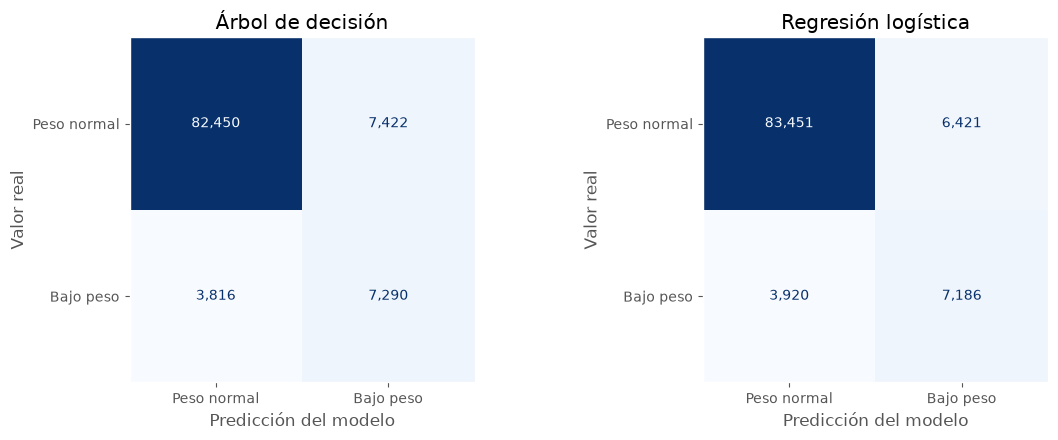

Árbol de decisión: detectados 7290 | no detectados 3816 | falsas alarmas 7422 | normales bien clasificados 82450
Regresión logística: detectados 7186 | no detectados 3920 | falsas alarmas 6421 | normales bien clasificados 83451


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (nombre, modelo), ax in zip(modelos.items(), axes):
    cm = confusion_matrix(y_test, modelo.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['Peso normal', 'Bajo peso']).plot(ax=ax, cmap='Blues', colorbar=False, values_format=',d')
    ax.set_title(nombre)
    ax.set_xlabel('Predicción del modelo')
    ax.set_ylabel('Valor real')
    ax.grid(False)
plt.tight_layout()
plt.show()

for nombre, modelo in modelos.items():
    # ravel() devuelve: verdaderos negativos, falsos positivos, falsos negativos, verdaderos positivos
    vn, fp, fn, vp = confusion_matrix(y_test, modelo.predict(X_test)).ravel()
    print(f'{nombre}: detectados {vp} | no detectados {fn} | falsas alarmas {fp} | normales bien clasificados {vn}')

**Lectura**, sobre los 11.106 casos reales de bajo peso del conjunto de prueba:

| | Árbol de decisión | Regresión logística |
|---|---|---|
| Casos de bajo peso detectados | 7.290 | 7.186 |
| Casos de bajo peso **no detectados** | 3.816 | 3.920 |
| Falsas alarmas | 7.422 | 6.421 |

La regresión logística detecta 104 casos menos que el árbol, pero genera 1.001 falsas alarmas menos. El error más grave para este problema son los **casos no detectados** (cerca de 3.900 en ambos modelos): son bebés con bajo peso que el modelo clasificó como normales. Como se vio en la fase 4, la mayoría son nacimientos a término, que los datos disponibles no permiten distinguir.

In [46]:
for nombre, modelo in modelos.items():
    print(f'===== {nombre} =====')
    print(classification_report(y_test, modelo.predict(X_test), target_names=['Peso normal', 'Bajo peso'], digits=3))

===== Árbol de decisión =====
              precision    recall  f1-score   support

 Peso normal      0.956     0.917     0.936     89872
   Bajo peso      0.496     0.656     0.565     11106

    accuracy                          0.889    100978
   macro avg      0.726     0.787     0.750    100978
weighted avg      0.905     0.889     0.895    100978

===== Regresión logística =====
              precision    recall  f1-score   support

 Peso normal      0.955     0.929     0.942     89872
   Bajo peso      0.528     0.647     0.582     11106

    accuracy                          0.898    100978
   macro avg      0.742     0.788     0.762    100978
weighted avg      0.908     0.898     0.902    100978



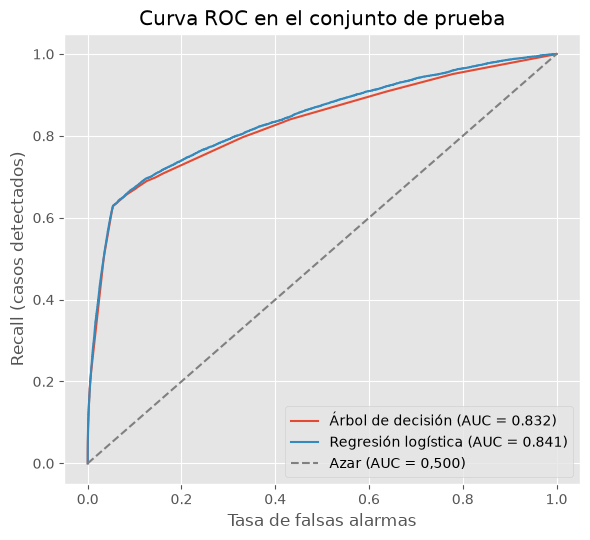

In [47]:
plt.figure(figsize=(6, 5.5))
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar (AUC = 0,500)')
plt.xlabel('Tasa de falsas alarmas')
plt.ylabel('Recall (casos detectados)')
plt.title('Curva ROC en el conjunto de prueba')
plt.legend()
plt.tight_layout()
plt.show()

La curva ROC confirma que ambos modelos están muy por encima del azar y que la logística queda ligeramente por encima del árbol en casi todo el recorrido.

## 5.4 ¿Hay sobreajuste?

In [48]:
comparacion = {}
for nombre, modelo in modelos.items():
    comparacion[f'{nombre} - entrenamiento'] = metricas(modelo, X_train, y_train)
    comparacion[f'{nombre} - prueba'] = metricas(modelo, X_test, y_test)
pd.DataFrame(comparacion).T

,exactitud,recall,precisión,F1,AUC
Árbol de decisión - entrenamiento,0.889,0.656,0.497,0.566,0.832
Árbol de decisión - prueba,0.889,0.656,0.496,0.565,0.832
Regresión logística - entrenamiento,0.898,0.645,0.530,0.582,0.842
Regresión logística - prueba,0.898,0.647,0.528,0.582,0.841


**Lectura:** las métricas en entrenamiento y en prueba son casi idénticas en los dos modelos. **No hay sobreajuste:** los modelos no memorizaron los datos, sino que aprendieron patrones que se mantienen en nacimientos que nunca vieron.

## 5.5 Punto de corte y significado del puntaje

El modelo no entrega directamente un "sí" o un "no", sino un puntaje entre 0 y 1. Por defecto se marca como riesgo todo lo que supere 0,5. Ese punto de corte se puede mover según cuántos casos se quieran detectar y cuántas alertas se puedan atender.

In [49]:
prob_test = modelo_logistica.predict_proba(X_test)[:, 1]

# predict() usa 0,5 como punto de corte; aquí se aplican otros valores sobre el puntaje
filas = []
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (prob_test >= umbral).astype(int)
    filas.append({'umbral': umbral,
                  'recall': round(recall_score(y_test, pred), 3),
                  'precisión': round(precision_score(y_test, pred), 3),
                  '% de gestantes marcadas como riesgo': round(pred.mean() * 100, 1)})
pd.DataFrame(filas)

,umbral,recall,precisión,% de gestantes marcadas como riesgo
0,0.2,0.955,0.133,78.7
1,0.3,0.822,0.218,41.5
2,0.4,0.710,0.373,20.9
3,0.5,0.647,0.528,13.5
4,0.6,0.630,0.586,11.8
5,0.7,0.628,0.591,11.7
6,0.8,0.615,0.598,11.3


**Lectura:** bajar el punto de corte a 0,3 sube el recall a 82 %, pero obliga a marcar como riesgo al 41,5 % de las gestantes y la precisión cae a 22 %. Subirlo por encima de 0,6 casi no cambia nada. Se mantiene **0,5**, que marca al 13,5 % de las gestantes y cumple el criterio de éxito. Una entidad con más capacidad de seguimiento podría preferir 0,4.

In [50]:
# ¿Qué porcentaje de bajo peso se observa realmente según el puntaje del modelo?
# Los nacimientos de prueba se dividen en 20 grupos del mismo tamaño, ordenados por puntaje
grupos, bordes = pd.qcut(prob_test, q=20, retbins=True)
tabla_puntaje = pd.DataFrame({'puntaje': prob_test, 'bajo_peso': y_test.values}).groupby(grupos, observed=True).agg(
    puntaje_min=('puntaje', 'min'), puntaje_max=('puntaje', 'max'),
    nacimientos=('bajo_peso', 'size'), pct_real_bajo_peso=('bajo_peso', 'mean')).reset_index(drop=True)
tabla_puntaje['pct_real_bajo_peso'] = (tabla_puntaje['pct_real_bajo_peso'] * 100).round(1)
tabla_puntaje.round(3)

,puntaje_min,puntaje_max,nacimientos,pct_real_bajo_peso
0,0.043,0.147,5049,1.5
1,0.147,0.167,5049,1.8
2,0.167,0.183,5049,2.6
3,0.183,0.197,5049,2.8
4,0.197,0.210,5049,3.0
5,0.210,0.223,5049,3.3
6,0.223,0.235,5048,3.9
7,0.235,0.248,5049,3.6
8,0.248,0.261,5049,4.2
9,0.261,0.274,5049,4.3


**Importante: el puntaje no es una probabilidad real.** Como el modelo se entrenó con `class_weight='balanced'`, sus puntajes están inflados. Entre los nacimientos con puntaje cercano a 0,3, solo alrededor del 5 % fue realmente de bajo peso, no el 30 %. En los dos grupos más altos (puntaje mayor a 0,86) la proporción real está entre 51,6 % y 72,7 %.

Se usan 20 grupos del mismo tamaño, de unos 5.000 nacimientos cada uno, en lugar de rangos fijos de 0,2. La razón es que la mayoría de los puntajes se concentra entre 0,2 y 0,4: con rangos fijos, casi todas las gestantes quedarían en el mismo rango y la aplicación mostraría el mismo porcentaje aunque cambiaran sus datos. Los porcentajes suben de un grupo al siguiente, salvo dos pequeñas inversiones (3,9 % y 3,6 %; 5,1 % y 4,6 %) que son variación normal entre grupos de este tamaño.

Por eso, en la aplicación no se debe mostrar el puntaje como "probabilidad de bajo peso". Se mostrará el **nivel de riesgo** junto con el porcentaje realmente observado en nacimientos con puntaje similar, que es lo que indica esta tabla.

## 5.6 Evaluación en el Meta

El destinatario de la herramienta es la Secretaría de Salud del Meta, así que se revisa si los modelos, entrenados con datos de todo el país, funcionan igual de bien en el departamento.

In [51]:
es_meta = X_test['DEPARTAMENTO_Meta'] == 1
print('Nacimientos del Meta en el conjunto de prueba:', es_meta.sum())
print('Casos de bajo peso entre ellos:', int(y_test[es_meta].sum()), f'({y_test[es_meta].mean() * 100:.1f} %)')

eval_meta = {}
for nombre, modelo in modelos.items():
    eval_meta[f'{nombre} - Meta'] = metricas(modelo, X_test[es_meta], y_test[es_meta])
    eval_meta[f'{nombre} - resto del país'] = metricas(modelo, X_test[~es_meta], y_test[~es_meta])
pd.DataFrame(eval_meta).T

Nacimientos del Meta en el conjunto de prueba: 2674
Casos de bajo peso entre ellos: 158 (5.9 %)


,exactitud,recall,precisión,F1,AUC
Árbol de decisión - Meta,0.940,0.665,0.495,0.568,0.850
Árbol de decisión - resto del país,0.887,0.656,0.496,0.565,0.831
Regresión logística - Meta,0.940,0.665,0.495,0.568,0.861
Regresión logística - resto del país,0.896,0.647,0.529,0.582,0.840


**Lectura:** en el Meta los modelos rinden igual o mejor que en el resto del país: recall de 66,5 % y AUC de 0,85 a 0,86. Esto respalda la decisión de entrenar con datos nacionales e incluir el departamento como variable.

Hay que leerlo con cautela: en el conjunto de prueba hay 2.674 nacimientos del Meta y solo 158 de bajo peso, así que estas cifras son menos estables que las nacionales.

## 5.7 Verificación del criterio de éxito

In [52]:
RECALL_MINIMO = 0.60
PRECISION_MINIMA = 0.45

verificacion = evaluacion[['recall', 'precisión', 'AUC']].copy()
verificacion['cumple recall'] = verificacion['recall'] >= RECALL_MINIMO
verificacion['cumple precisión'] = verificacion['precisión'] >= PRECISION_MINIMA
# La primera fila de la tabla es la línea base
verificacion['supera línea base'] = verificacion['recall'] > evaluacion.iloc[0]['recall']
verificacion

,recall,precisión,AUC,cumple recall,cumple precisión,supera línea base
"Línea base (siempre ""peso normal"")",0.000,0.000,0.500,False,False,False
Árbol de decisión,0.656,0.496,0.832,True,True,True
Regresión logística,0.647,0.528,0.841,True,True,True


---
## Conclusiones de la fase 5

1. **Los dos modelos cumplen el criterio de éxito:** recall superior a 60 %, precisión superior a 45 % y muy por encima de la línea base.
2. **No hay sobreajuste** y los resultados se mantienen en el Meta.
3. **Modelo seleccionado para el despliegue: regresión logística.** Tiene mejor AUC y precisión, genera cerca de mil falsas alarmas menos con un recall casi igual, y produce un puntaje continuo que permite graduar el nivel de riesgo. El árbol de decisión se conserva como modelo de apoyo para **explicar** qué factores pesan y en qué orden, porque sus reglas se pueden leer directamente.
4. **Limitaciones:**
   - Cerca de un tercio de los casos de bajo peso no se detecta, sobre todo los nacidos a término.
   - El modelo depende de las semanas de gestación: es útil cuando ya se conoce o se puede anticipar la edad gestacional, no como predictor temprano a partir del perfil de la madre.
   - El puntaje no es una probabilidad real y debe presentarse como nivel de riesgo.
   - Los datos son de un solo año (2023) y solo incluyen las variables del certificado de nacido vivo.

**Pendiente para la fase 6 (despliegue):** exportar el modelo y construir la aplicación.

---
# Fase 6. Despliegue

El despliegue pone el modelo a disposición de quien lo va a usar. Se hace en dos partes:

1. **En este notebook:** se exporta el modelo seleccionado (regresión logística) junto con todo lo necesario para usarlo, en el archivo `modelo_bajo_peso.joblib`.
2. **En la aplicación (`app.py`):** una interfaz en Streamlit carga ese archivo, recibe los datos de la gestante y muestra el nivel de riesgo.

## 6.1 Exportación del modelo

No basta con guardar el modelo. La aplicación debe preparar los datos del formulario igual que en la fase 3, así que también se guardan las columnas, el escalador, las opciones válidas de cada variable y la tabla de niveles de riesgo.

In [53]:
import joblib
import sklearn

# Opciones válidas de cada variable categórica (para los menús del formulario)
opciones = {col: sorted(datos[col].dropna().unique().tolist()) for col in categoricas}
opciones['NIV_EDUP'].append('Sin información')

# Niveles de riesgo, a partir de la tabla de la sección 5.5 (porcentaje real observado en la prueba)
limites = bordes.copy()
limites[0], limites[-1] = 0.0, 1.0      # para cubrir cualquier puntaje posible
pct = tabla_puntaje['pct_real_bajo_peso'].values
niveles_riesgo = pd.DataFrame({
    'puntaje_min': limites[:-1],
    'puntaje_max': limites[1:],
    'nivel': np.where(pct < 11.0, 'Bajo', np.where(pct < 50.0, 'Medio', 'Alto')),
    'pct_real_bajo_peso': pct,
})

artefactos = {
    'modelo': modelo_logistica,
    'columnas': X_train.columns.tolist(),    # las columnas que espera el modelo, en orden
    'categoricas': categoricas,
    'numericas': numericas,
    'escalador': escalador,
    'opciones': opciones,
    'niveles_riesgo': niveles_riesgo,
    'version_sklearn': sklearn.__version__,
}
joblib.dump(artefactos, 'modelo_bajo_peso.joblib')

print('Guardado: modelo_bajo_peso.joblib')
print('Versión de scikit-learn usada:', sklearn.__version__)
niveles_riesgo

Guardado: modelo_bajo_peso.joblib
Versión de scikit-learn usada: 1.6.1


,puntaje_min,puntaje_max,nivel,pct_real_bajo_peso
0,0.000000,0.146797,Bajo,1.5
1,0.146797,0.166940,Bajo,1.8
2,0.166940,0.182842,Bajo,2.6
3,0.182842,0.196627,Bajo,2.8
4,0.196627,0.209745,Bajo,3.0
5,0.209745,0.222568,Bajo,3.3
6,0.222568,0.234727,Bajo,3.9
7,0.234727,0.247574,Bajo,3.6
8,0.247574,0.260520,Bajo,4.2
9,0.260520,0.274132,Bajo,4.3


Los niveles de riesgo se definen con el porcentaje de bajo peso realmente observado en cada grupo de la sección 5.5, comparado con el promedio nacional de 11,0 %: **bajo** si está por debajo del promedio, **medio** si está por encima pero es menor al 50 %, y **alto** si la mitad o más de esos nacimientos fue de bajo peso. Junto al nivel se guarda ese porcentaje, que es lo que la aplicación debe mostrar en lugar del puntaje.

## 6.2 Prueba del modelo exportado

Se carga el archivo tal como lo hará la aplicación y se predicen dos casos de ejemplo. La función `predecir_riesgo` es la que debe reutilizarse en `app.py`.

In [54]:
def predecir_riesgo(caso, A):
    """Recibe los datos de una gestante (diccionario) y devuelve puntaje, nivel de riesgo y % real observado."""
    fila = pd.DataFrame([caso])

    # Verificar que cada valor categórico sea una opción válida
    for col in A['categoricas']:
        assert fila.loc[0, col] in A['opciones'][col], f'Valor no válido en {col}: {fila.loc[0, col]}'

    # Misma preparación que en la fase 3: one-hot, mismas columnas en el mismo orden, y escalado
    fila = pd.get_dummies(fila, columns=A['categoricas'], dtype='int8')
    fila = fila.reindex(columns=A['columnas'], fill_value=0)
    fila[A['numericas']] = A['escalador'].transform(fila[A['numericas']])

    puntaje = A['modelo'].predict_proba(fila)[0, 1]
    n = A['niveles_riesgo']
    rango = n[(puntaje >= n['puntaje_min']) & (puntaje <= n['puntaje_max'])].iloc[0]
    return {'puntaje': round(float(puntaje), 3), 'nivel': rango['nivel'],
            'pct_real_bajo_peso': float(rango['pct_real_bajo_peso'])}


# Se carga el archivo exportado, igual que lo hará la aplicación
A = joblib.load('modelo_bajo_peso.joblib')

caso_1 = {'T_GES_AGRU_CIE': '37 a 41', 'MUL_PARTO': 'Simple', 'EDAD_MADRE': '25-29',
          'EST_CIVM': 'Unión libre 2 años o más', 'NIV_EDUM': 'Media', 'NIV_EDUP': 'Media',
          'DEPARTAMENTO': 'Meta', 'AREA_RES': 'Cabecera municipal', 'SEG_SOCIAL': 'Subsidiado',
          'IDPERTET': 'Ninguno', 'SEXO': 'Masculino',
          'NUMCONSUL': 7, 'N_HIJOSV': 2, 'N_EMB': 2, 'EDAD_PADRE': 30}

# Mismo caso, pero con parto prematuro y embarazo doble
caso_2 = dict(caso_1, T_GES_AGRU_CIE='28 a 36', MUL_PARTO='Doble')

for nombre, caso in [('Caso 1: a término, embarazo simple', caso_1), ('Caso 2: prematuro, embarazo doble', caso_2)]:
    r = predecir_riesgo(caso, A)
    print(f"{nombre}\n   Nivel de riesgo: {r['nivel']} | puntaje: {r['puntaje']} | "
          f"en nacimientos con puntaje similar, el {r['pct_real_bajo_peso']} % fue de bajo peso\n")

Caso 1: a término, embarazo simple
   Nivel de riesgo: Bajo | puntaje: 0.126 | en nacimientos con puntaje similar, el 1.5 % fue de bajo peso

Caso 2: prematuro, embarazo doble
   Nivel de riesgo: Alto | puntaje: 0.982 | en nacimientos con puntaje similar, el 72.7 % fue de bajo peso



In [55]:
# Opciones que debe ofrecer el formulario de la aplicación
for col, valores in A['opciones'].items():
    print(f'{col}: {valores}')
print('\nVariables numéricas:', A['numericas'])

T_GES_AGRU_CIE: ['28 a 36', '37 a 41', '42 o más', 'Menos de 28']
MUL_PARTO: ['Doble', 'Simple', 'Triple o más']
EDAD_MADRE: ['10-14', '15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45 o más']
EST_CIVM: ['Casada', 'Separada o viuda', 'Soltera', 'Unión libre 2 años o más', 'Unión libre menos de 2 años']
NIV_EDUM: ['Media', 'Ninguno o preescolar', 'Posgrado', 'Primaria', 'Profesional', 'Secundaria', 'Técnica o tecnológica']
NIV_EDUP: ['Media', 'Ninguno o preescolar', 'Posgrado', 'Primaria', 'Profesional', 'Secundaria', 'Técnica o tecnológica', 'Sin información']
DEPARTAMENTO: ['Amazonas', 'Antioquia', 'Arauca', 'Atlántico', 'Bogotá', 'Bolívar', 'Boyacá', 'Caldas', 'Caquetá', 'Casanare', 'Cauca', 'Cesar', 'Chocó', 'Cundinamarca', 'Córdoba', 'Guainía', 'Guaviare', 'Huila', 'La Guajira', 'Magdalena', 'Meta', 'Nariño', 'Norte de Santander', 'Putumayo', 'Quindío', 'Risaralda', 'San Andrés', 'Santander', 'Sucre', 'Tolima', 'Valle del Cauca', 'Vaupés', 'Vichada']
AREA_RES: ['Cabecera mu

**Lectura:** el modelo exportado responde de forma coherente. La gestante del caso 1 (a término, embarazo simple, residente en el Meta) queda en riesgo bajo; al cambiar solo la gestación a prematura y el embarazo a doble, pasa a riesgo alto.


---
## Conclusiones de la fase 6

1. El modelo quedó exportado en `modelo_bajo_peso.joblib`, con todo lo necesario para usarlo fuera del notebook.
2. La función `predecir_riesgo` reproduce la preparación de la fase 3 y entrega el resultado como nivel de riesgo, no como probabilidad.

